## Automating Regional Briefings
Author: Smitha Mahesh, Eric Englin, Sophie Son

Purpose: To complete the analyses and visualizations required for the region-level briefings. 

In [2]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.patches as mpatches
import seaborn as sns
import docx

In [3]:
myworkingdirectory = r"C:\Users\Sophie.Kaye\DOT OST\volpe-proj-VU16A100 - Transportation Safety Program\Region Briefing"
os.chdir(myworkingdirectory)

In [4]:
analysis_2022 = pd.read_csv(".//Data//Output Data//analysis_database_2022.csv")

In [5]:
analysis_2022.shape

(207097, 53)

In [6]:
park_info = pd.read_csv(".//Data//Reference Data/Park_Info_Table.csv")
park_info = park_info.rename(columns={'UNIT_CODE':'Park','REGION':'RGN'})

In [7]:
analysis_2022.columns

Index(['INCID_NO', 'NUM_OCC', '5_mph', '10_mph', '15_mph', '20_mph', '25_mph',
       '30_mph', '35_mph', '40_mph', '45_mph', '50_mph', '55_mph', '60_mph',
       '65_mph', '70_mph', '75_mph', 'no_posted_speed', 'Crosswalk',
       'Outside a Crosswalk', 'No Injury', 'Possible Injury',
       'Non-incapacitating Injury', 'Incapacitating Injury', 'Fatality',
       'Unknown Injury', 'Num_Fatalities', 'Num_Injuries', 'Injury or Fatal',
       'Pedestrian', 'Bicycle', 'Pedacycle', 'VRU', 'HorseLlama', 'Cow',
       'Deer', 'Elk', 'Moose', 'Buffalo', 'Bear', 'Antelope', 'SheepGoats',
       'OtherWild', 'OtherDomestic', 'Involving Animal', 'LATITUDE',
       'LONGITUDE', 'Park', 'RGN', 'CRASH_DATE', 'CRASH_TIME', 'CRASH_YEAR',
       'database'],
      dtype='object')

## Available Data Fields

In [8]:
safety_studies = pd.read_excel(".//Safety Studies//NPS_TSP_Safety_Study_Catalog_2010-2020.xlsx",  "Safety Studies 2010-2020 ")
safety_studies['RGN'] = safety_studies['Legacy Region Abbreviation']
safety_studies['INCID_NO']=1

In [9]:
safety_analyst_parks = pd.read_excel(".//Data//Safety Analyst//Safety Analyst Parks.xlsx")
safety_analyst_parks['Safety Analyst Park']=1

In [10]:
analysis_2022_merge = analysis_2022.merge(safety_analyst_parks, on="Park", how = "left")

In [11]:
analysis_2022_merge.shape, analysis_2022.shape

((207097, 55), (207097, 53))

In [12]:
prmp = pd.read_excel(".//Data//PRMP//NPS Fatal MVCs No PII CY2014-Present_07OCT22_clean.xlsx",  "Sheet1")
prmp['RGN'] = prmp['NPS Region']
prmp['Park'] = prmp['ParkAlpha']


### Table 1: Overview of Data Sources

In [13]:
analysis_2022_merge.head()

,INCID_NO,NUM_OCC,5_mph,10_mph,15_mph,20_mph,25_mph,30_mph,35_mph,40_mph,...,LATITUDE,LONGITUDE,Park,RGN,CRASH_DATE,CRASH_TIME,CRASH_YEAR,database,Region,Safety Analyst Park
0,ABLI070425075000,1,0,0,0,0,0,0,0,0,...,NaN,NaN,ABLI,SER,4/25/2007,750,2007.0,CDS,NaN,NaN
1,ABLI070804175500,0,1,0,0,0,0,0,0,0,...,NaN,NaN,ABLI,SER,8/4/2007,1755,2007.0,CDS,NaN,NaN
2,ABLI091117170900,2,0,0,0,0,1,0,0,0,...,NaN,NaN,ABLI,SER,11/17/2009,1709,2009.0,CDS,NaN,NaN
3,ABLI121009110000,2,0,0,0,0,1,0,0,0,...,NaN,NaN,ABLI,SER,10/9/2012,1100,2012.0,CDS,NaN,NaN
4,ABLI140610163500,1,0,0,0,0,0,0,0,0,...,38.91205,-76.93412,ABLI,SER,6/10/2014,1635,2014.0,CDS,NaN,NaN


In [14]:
analysis_2022_merge.LATITUDE.isnull()==False

0         False
1         False
2         False
3         False
4          True
          ...  
207092    False
207093    False
207094    False
207095    False
207096    False
Name: LATITUDE, Length: 207097, dtype: bool

In [15]:
def pull_source_table_data(df, region, field, filter_value):
    df = df.loc[df['RGN']==region]
    df = df.loc[df[field]==filter_value]
    
    if field ==  'Safety Analyst Park':
        df = df.loc[df["CRASH_YEAR"]>2006]
        df = df.loc[df["CRASH_YEAR"]<2013]
        df = df.loc[df.LATITUDE.isnull()==False]
        
    parks, crashes = df.groupby("Park").agg({
        'INCID_NO':'count',
    }).reset_index().agg({
        "Park":"count",
        'INCID_NO':sum,
    })
    
    parks = str(parks) + " Park Units"
    
    crashes = "{:,}".format(crashes) + " Crash Reports"
    
    return parks, crashes

def make_source_table(region):
    CDS_parks, CDS_crash_reports = pull_source_table_data(analysis_2022_merge, region, 'database', 'CDS')
    IMARS_parks, IMARS_crash_reports = pull_source_table_data(analysis_2022_merge, region, 'database', 'IMARS')
    SA_parks, SA_crash_reports = pull_source_table_data(analysis_2022_merge, region, 'Safety Analyst Park', 1)
    SS_parks, SS_crash_reports = pull_source_table_data(safety_studies, region, 'INCID_NO', 1)
    PRMP_parks, PRMP_crash_reports = pull_source_table_data(prmp, region, 'INCID_NO', 1)
    source_list = []
    parks_list = [CDS_parks, IMARS_parks, PRMP_parks, SA_parks, SS_parks]
    crash_reports_list = [CDS_crash_reports, IMARS_crash_reports, PRMP_crash_reports, SA_crash_reports, SS_crash_reports]
    

    final_df = pd.DataFrame({
        "Source":["Crash Data System (CDS)", 
                  "Incident Management Analysis and Reporting System (IMARS)",
                  "Public Risk Management Program (PRMP)",
                  'Safety Analyst', "Safety Studies"],
        "Locations": parks_list,
        'Years': ["1989-2013", "2012-present", "2014-2021","2007-2012", "2010-present"],
        "Quantity of Data": crash_reports_list
    })
    
    return final_df

In [16]:
make_source_table("IMR")

,Source,Locations,Years,Quantity of Data
0,Crash Data System (CDS),58 Park Units,1989-2013,"32,893 Crash Reports"
1,Incident Management Analysis and Reporting Sys...,52 Park Units,2012-present,"2,642 Crash Reports"
2,Public Risk Management Program (PRMP),16 Park Units,2014-2021,46 Crash Reports
3,Safety Analyst,7 Park Units,2007-2012,"3,960 Crash Reports"
4,Safety Studies,12 Park Units,2010-present,21 Crash Reports


### Table 2: Data Dictionary

In [17]:
data_dictionary = pd.DataFrame({
"Term": ['All crashes','Analysis database','CDS', 'Coordinates','Crash report','Crashes involving wildlife',
         'Crashes resulting in an injury/fatality','Crosswalk','Excluded from analysis','Fatalities',
         'Outside a crosswalk','Posted speed','Regardless of involvement','Regardless of outcome','Serious Injuries',
         'Top 10 Parks','Total crashes','Total injuries','Type of animal','Unlinked','VRU','Wildlife'],
"Definition": ['Interchangeable with “Total crashes” – both terms encompass every crash report in the analysis database',
              'Set of the best-quality crash reports from IMARS and CDS/STARS recorded between 1990 and 2021 that was used to generate the figures and tables of crash statistics in sections 1.2, 1.3.2, and 2.1',
              'Crash Data System – interchangeable with “CDS/STARS” as both raw databases were combined for this analysis',
              'Numerical indicators of crash location in the form of latitude and longitude decimal degrees',
              'A single crash identification number, which may involve multiple persons or vehicles', 
              'Derived variable based on crash reports in which at least one of the following were mentioned: collisions with animals, drivers performing unplanned maneuvers to avoid striking an animal, and/or animals in the roadway FOOTNOTE',
              'Number of crash reports in which at least one person involved was injured or killed FOOTNOTE',
              'Location of vulnerable road user, explicitly stated in crash report FOOTNOTE',
              'A crash report from the raw CDS/STARS or IMARS datasets that was not included in the final analysis database due to lack of identifiable Park name',
              'Number of lives lost FOOTNOTE – does not include any animals involved and does not necessarily refer to the vulnerable road user(s) involved. Refers to any human involved in the crash.',
              'Derived variable from crash reports in which the vulnerable road user’s location was known, but not classified as a pedestrian crossing (does not include unknown or null vulnerable road user locations) FOOTNOTE',
              'Marked speed limit on the roadway in miles per hour – the vehicle(s) involved may have actually been traveling faster or slower) FOOTNOTE',
              'All crash reports in the analysis database, which may encompass crashes involving vulnerable road users and/or wildlife',
              'All crash reports in the analysis database, which may encompass crashes resulting in injuries, fatalities, and/or property damage',
              'Defined as “Incapacitating injuries” in raw data FOOTNOTE', 'Parks with the most regional total crashes',
              'Interchangeable with “All crashes”  – both terms encompass every crash report in the analysis database',
              'Conservative estimate based on the sum of the “Possible Injury”, “Non-Incapacitating Injury”, and “Incapacitating Injury” data attributes FOOTNOTE – does not include any animals involved and does not necessarily refer to the vulnerable road user(s) involved. Refers to any human involved in the crash.',
              'Categories taken from the IMARS Classification table First_Harmful_Event variable data attributes. Note that CDS/STARS does not specify type of animal in the crash reports for records involving wildlife.',
              'Original crash report for which the Crash data table was populated, but the Passenger and Vehicle tables were not populated',
              'Vulnerable Road User – a derived variable based on crash reports in which at least one of the following were mentioned: “Pedestrian”, “Cyclist”, and/or “Pedalcyclist” FOOTNOTE',
              'Animals involved in the crash, both wild and domestic']
})

doc_name = './22-23/Drafted Deliverables/NPS TSP Regional Briefing Draft 22-23 - blank.docx' # start wtih blank Volpe template
doc = docx.Document(doc_name)
doc.add_heading("Region-Level Analyses Terms and Definitions")
t = doc.add_table(data_dictionary.shape[0]+1, data_dictionary.shape[1], style="Grid Table 5 Dark Accent 1") # blue alternating

for j in range(data_dictionary.shape[-1]):
    t.cell(0,j).text = data_dictionary.columns[j]

for i in range(data_dictionary.shape[0]):
    for j in range(data_dictionary.shape[-1]):
        t.cell(i+1,j).text = str(data_dictionary.values[i,j])
        
doc_name_new = './22-23\Drafted Deliverables\Figures/Data Dictionary.docx'
doc.save(doc_name_new)

## Regional Trends

### Table 3: Crash Outcomes by Park

In [18]:
def create_park_table(region):
    # create dataframe for number of serious injuries, number of fatalities, number of crashes that resulted in an injury or fatality by park   
    region = analysis_2022.loc[analysis_2022['RGN']==region]
    region_slim = region[['Park', 'Num_Fatalities', 'Incapacitating Injury', 'Injury or Fatal']]
    region_parks = region_slim.groupby(by=['Park'], as_index=False).sum()
    region_parks['Number of Fatalities'] = region_parks['Num_Fatalities'].astype(int)
    region_parks['Number of Serious Injuries'] = region_parks['Incapacitating Injury'].astype(int)
    region_parks['Number of Crashes Resulting in an Injury or Fatality'] = region_parks['Injury or Fatal'].astype(int)
    region_parks = region_parks.drop(columns={'Num_Fatalities','Num_Fatalities', 'Incapacitating Injury', 'Injury or Fatal'})
    region_parks = region_parks.sort_values(by = ["Number of Fatalities","Number of Serious Injuries","Number of Crashes Resulting in an Injury or Fatality"], ascending = False)


    return region_parks

In [19]:
def make_park_table(region):
    df = create_park_table(region)
    doc_name = './22-23/Drafted Deliverables/NPS TSP Regional Briefing Draft 22-23 - blank.docx' # start wtih blank Volpe template
    doc = docx.Document(doc_name)
    doc.add_heading("Injury & fatality, at All Region Park Units")
    t = doc.add_table(df.shape[0]+1, df.shape[1], style="Grid Table 5 Dark Accent 1") # blue alternating

    for j in range(df.shape[-1]):
        t.cell(0,j).text = df.columns[j]

    for i in range(df.shape[0]):
        for j in range(df.shape[-1]):
            t.cell(i+1,j).text = str(df.values[i,j])
    doc_name_new = './22-23\Drafted Deliverables\Figures/Park level tables/' + region + ".docx"
    doc.save(doc_name_new)

In [20]:
# test table; once satisfied, run all seven to save separately from companion document
make_park_table("NCR")

### All Crashes

### Figure 1: All Crashes by Speed Limit

In [21]:
def create_posted_speed_fig(region):
    from matplotlib.ticker import MaxNLocator
    df = analysis_2022.loc[analysis_2022['RGN']==region]
    speed_list = [5,10,15,20,25,30,35,40,45,50,55,60,65,70,75]
    speed_columns = ['5_mph', '10_mph', '15_mph', '20_mph', '25_mph','30_mph', '35_mph', '40_mph', '45_mph', '50_mph', '55_mph', '60_mph','65_mph', '70_mph', '75_mph']
    fatalities = []
    serious_injuries = []
    crashes = []
    
    for i in speed_columns:
        num_fatalities = df.loc[df[i]==1]['Num_Fatalities'].sum()
        fatalities.append(num_fatalities)
        num_serious_injuries = df.loc[df[i]==1]['Incapacitating Injury'].sum()
        serious_injuries.append(num_serious_injuries)    
        num_crashes = df.loc[df[i]==1].shape[0]
        crashes.append(num_crashes)
    
    # set up main figure with three subplots
    plt.style.use('seaborn')
    sns.set(rc={'axes.facecolor':'1', 'figure.facecolor':'white', 'patch.linewidth': 0.0})
    fig, ax = plt.subplots(3,1,figsize=(20,15))
    tick_spacing = 5
    fig.suptitle('All Crashes by Speed Limit', fontsize=30)

    # subplot data
    ax[0].bar(speed_list, fatalities, width = 5, hatch = "\\", edgecolor = "black", linewidth=2)
    ax[1].bar(speed_list, serious_injuries, width = 5, hatch = "/", edgecolor = "black", linewidth=2)
    ax[2].bar(speed_list, crashes, width = 5, hatch = "x", edgecolor = "black", linewidth=2)

    # annotate all plots with bar totals
    rects = ax[0].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[0].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    rects = ax[1].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[1].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    rects = ax[2].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[2].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    # format each subplot
    ax[0].set_title("Fatalities",fontsize= 22, pad = 20)
    #ax[0].set_ylim([0, 300])
    ax[0].set_xlim([2, 78])
    ax[0].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
    ax[0].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
    ax[0].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[0].set_ylabel("# of Fatalities", fontsize = 22)#ylabel
    ax[0].tick_params(axis='x', which='major', labelsize=16)
    ax[0].tick_params(axis='y', which='major', labelsize=16)
    ax[0].tick_params(axis='both', which='minor', labelsize=8)

    ax[1].set_title("Serious Injuries",fontsize= 22, pad = 20)
    #ax[1].set_ylim([0, 3000])
    ax[1].set_xlim([2, 78])
    ax[1].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
    ax[1].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
    ax[1].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[1].set_ylabel("# of Serious Injuries", fontsize = 19)#ylabel
    ax[1].tick_params(axis='x', which='major', labelsize=16)
    ax[1].tick_params(axis='y', which='major', labelsize=16)
    ax[1].tick_params(axis='both', which='minor', labelsize=8)

    ax[2].set_title("Crash Reports: Regardless of Outcome",fontsize= 22, pad = 20)
    #ax[2].set_ylim([0, 40000])
    ax[2].set_xlim([2, 78])
    ax[2].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
    ax[2].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
    ax[2].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[2].set_xlabel('Speed Limit',fontsize = 26) #xlabel
    ax[2].set_ylabel("# of Crash Reports", fontsize = 20)#ylabel
    ax[2].tick_params(axis='x', which='major', labelsize=16)
    ax[2].tick_params(axis='y', which='major', labelsize=16)
    ax[2].tick_params(axis='both', which='minor', labelsize=8)

    # set the spacing between subplots
    plt.subplots_adjust(bottom=0.1, top=0.9, wspace=0.4, hspace=0.4)
    
    doc_name = './22-23\Drafted Deliverables\Figures/Speed Limit Figures/' + region + ".png"
    
    plt.savefig(doc_name)


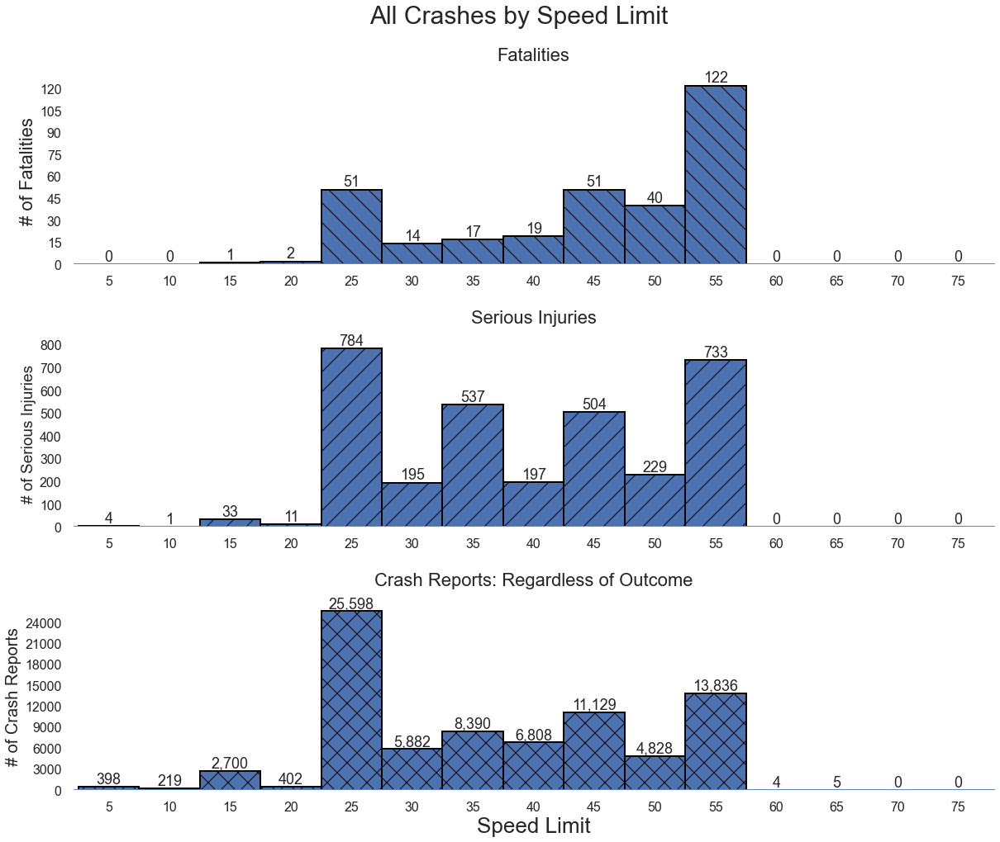

In [22]:
# test figure; once satisfied, run all seven to save separately from companion document
create_posted_speed_fig("NCR")

### Figure 2: All Crashes Resulting in an Injury or Fatality

In [23]:
def create_inj_or_fatal_fig(region):
    from matplotlib.ticker import MaxNLocator
    df = analysis_2022.loc[analysis_2022['RGN']==region]
    speed_list = [5,10,15,20,25,30,35,40,45,50,55,60,65,70,75]
    speed_columns = ['5_mph', '10_mph', '15_mph', '20_mph', '25_mph','30_mph', '35_mph', '40_mph', '45_mph', '50_mph', '55_mph', '60_mph','65_mph', '70_mph', '75_mph']
    inj_or_fatal = df.loc[df['Injury or Fatal']==1]
    vru_inj_or_fatal = inj_or_fatal.loc[inj_or_fatal['VRU']==1]
    animal_inj_or_fatal = inj_or_fatal.loc[inj_or_fatal['Involving Animal']==1]
    VRU_crashes = []
    wildlife_crashes = []
    all_crashes = []

    for i in speed_columns:
        num_VRU_crashes = vru_inj_or_fatal.loc[vru_inj_or_fatal[i]==1].shape[0]
        VRU_crashes.append(num_VRU_crashes)
        num_wildlife_crashes = animal_inj_or_fatal.loc[animal_inj_or_fatal[i]==1].shape[0]
        wildlife_crashes.append(num_wildlife_crashes)    
        num_all_crashes = inj_or_fatal.loc[inj_or_fatal[i]==1].shape[0]
        all_crashes.append(num_all_crashes)
    
   # set up main figure with three subplots
    plt.style.use('seaborn')
    sns.set(rc={'axes.facecolor':'1', 'figure.facecolor':'white', 'patch.linewidth': 0.0})
    fig, ax = plt.subplots(3,1,figsize=(20,15))
    tick_spacing = 5
    fig.suptitle('Crashes Resulting in an Injury or Fatality', fontsize=30)

    # subplot data
    ax[0].bar(speed_list, VRU_crashes, width = 5, hatch = "\\", color = 'sienna', edgecolor = "black", linewidth=2)
    ax[1].bar(speed_list, wildlife_crashes, width = 5, hatch = "/", color = 'darkolivegreen', edgecolor = "black", linewidth=2)
    ax[2].bar(speed_list, all_crashes, width = 5, hatch = "x", edgecolor = "black", linewidth=2)

    # annotate all plots with bar totals
    rects = ax[0].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[0].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    rects = ax[1].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[1].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    rects = ax[2].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[2].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    # format each subplot
    ax[0].set_title("Crashes Involving VRUs",fontsize= 22, pad = 20)
    #ax[0].set_ylim([0, 500])
    ax[0].set_xlim([2, 78])
    ax[0].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
    ax[0].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
    ax[0].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[0].set_ylabel("# of Crash Reports", fontsize = 22)#ylabel
    ax[0].tick_params(axis='x', which='major', labelsize=16)
    ax[0].tick_params(axis='y', which='major', labelsize=16)
    ax[0].tick_params(axis='both', which='minor', labelsize=8)

    ax[1].set_title("Crashes Involving Wildlife",fontsize= 22, pad = 20)
    #ax[1].set_ylim([0, 800])
    ax[1].set_xlim([2, 78])
    ax[1].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
    ax[1].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
    ax[1].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[1].set_ylabel("# of Crash Reports", fontsize = 22)#ylabel
    ax[1].tick_params(axis='x', which='major', labelsize=16)
    ax[1].tick_params(axis='y', which='major', labelsize=16)
    ax[1].tick_params(axis='both', which='minor', labelsize=8)

    ax[2].set_title("Crash Reports: Regardless of Involvement",fontsize= 22, pad = 20)
    #ax[2].set_ylim([0, 10000])
    ax[2].set_xlim([2, 78])
    ax[2].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
    ax[2].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
    ax[2].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[2].set_xlabel('Speed Limit',fontsize = 26) #xlabel
    ax[2].set_ylabel("# of Crash Reports", fontsize = 22)#ylabel
    ax[2].tick_params(axis='x', which='major', labelsize=16)
    ax[2].tick_params(axis='y', which='major', labelsize=16)
    ax[2].tick_params(axis='both', which='minor', labelsize=8)

    # set the spacing between subplots
    plt.subplots_adjust(bottom=0.1, top=0.9, wspace=0.4, hspace=0.4)
    
    doc_name = './22-23\Drafted Deliverables\Figures/Injury or Fatal Figures/' + region + ".png"
    
    plt.savefig(doc_name)


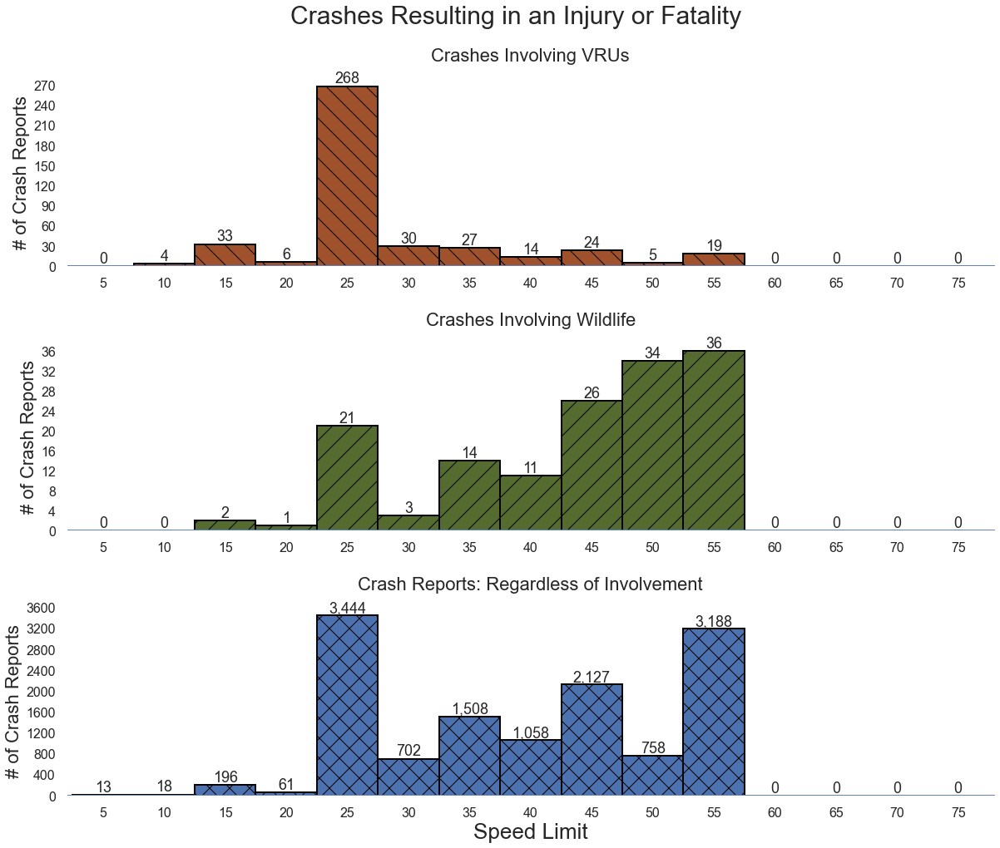

In [24]:
# test figure; once satisfied, run all seven to save separately from companion document
create_inj_or_fatal_fig("NCR")

### Wildlife crashes

### Table 4: Crashes Involving Wildlife, Regional and National 

In [25]:
def create_wildlife_crashes_table(region):
    # create dataframe for % of total crashes involving wildlife, % of wildlife crashes resulting in an injury or fatality, serious injuries and fatalities in wildlife crashes   

    rgn = analysis_2022.loc[analysis_2022['RGN']==region]
    animal = analysis_2022.loc[analysis_2022['Involving Animal']==1]
    animal_inj_or_fatal = animal.loc[animal['Injury or Fatal']==1]
    animal_region = animal.loc[animal['RGN']==region]
    animal_inj_or_fatal_region = animal_region.loc[animal_region['Injury or Fatal']==1]
    #animal_total_crashes_region = animal_inj_or_fatal_region.shape[0]
    animal_percent_region = round(animal_region.shape[0]/rgn.shape[0]*100,2)
    animal_inj_or_fatal_percent_region = round(animal_inj_or_fatal_region.shape[0]/animal_region.shape[0]*100,2)
    #animal_injury_region = int(animal_region['Num_Injuries'].sum())
    animal_serious_injury_region = int(animal_region['Incapacitating Injury'].sum())
    animal_fatals_region = int(animal_region['Num_Fatalities'].sum())
        
    #animal_total_crashes = animal_inj_or_fatal.shape[0]
    animal_percent = round(animal.shape[0]/analysis_2022.shape[0]*100,2)
    animal_inj_or_fatal_percent = round(animal_inj_or_fatal.shape[0]/animal.shape[0]*100,2)
    #animal_injury = int(animal['Num_Injuries'].sum())
    animal_serious_injury = int(animal['Incapacitating Injury'].sum())
    animal_fatals = int(animal['Num_Fatalities'].sum())
    
    df_final = pd.DataFrame({
    "Fields": ["Percent of Total Crashes", "Percent of Wildlife Crashes that Resulted in an Injury/Fatality", "Number of Serious Injuries", "Number of Fatalities"],
    region: [str(animal_percent_region) + "%", str(animal_inj_or_fatal_percent_region) + "%", animal_serious_injury_region, animal_fatals_region], 
    "National": [str(animal_percent) + "%", str(animal_inj_or_fatal_percent) + "%", animal_serious_injury, animal_fatals]
     })
    
    return df_final

In [26]:
def make_wildlife_crashes_table(region):
    df = create_wildlife_crashes_table(region)
    doc_name = './22-23/Drafted Deliverables/NPS TSP Regional Briefing Draft 22-23 - blank.docx' # start with blank Volpe template
    doc = docx.Document(doc_name)
    doc.add_heading("Crashes Involving Wildlife, Regional and National")
    t = doc.add_table(df.shape[0]+1, df.shape[1], style="Grid Table 5 Dark Accent 6") # green alternating

    for j in range(df.shape[-1]):
        t.cell(0,j).text = df.columns[j]

    for i in range(df.shape[0]):
        for j in range(df.shape[-1]):
            t.cell(i+1,j).text = str(df.values[i,j])
    doc_name_new = './22-23\Drafted Deliverables\Figures/Wildlife Tables/' + region + ".docx"
    doc.save(doc_name_new)

In [27]:
# test table; once satisfied, run all seven to save separately from companion document
make_wildlife_crashes_table("NCR")

### Figure 3: Wildlife Crashes by Speed Limit

In [28]:
def create_posted_speed_fig_animals(region):
    from matplotlib.ticker import MaxNLocator
    df = analysis_2022.loc[analysis_2022['RGN']==region]   
    speed_list = [5,10,15,20,25,30,35,40,45,50,55,60,65,70,75]
    speed_columns = ['5_mph', '10_mph', '15_mph', '20_mph', '25_mph','30_mph', '35_mph', '40_mph', '45_mph', '50_mph', '55_mph', '60_mph','65_mph', '70_mph', '75_mph']
    animal = df.loc[df['Involving Animal']==1]
    animal_inj_or_fatal = animal.loc[animal['Injury or Fatal']==1]
    animal_fatalities = []
    animal_serious_injuries = []
    animal_crashes = []

    for i in speed_columns:
        num_animal_fatalities = animal.loc[animal[i]==1]['Num_Fatalities'].sum()
        animal_fatalities.append(num_animal_fatalities)
        num_animal_serious_injuries = animal.loc[animal[i]==1]['Incapacitating Injury'].sum()
        animal_serious_injuries.append(num_animal_serious_injuries)    
        num_animal_crashes = animal.loc[animal[i]==1].shape[0]
        #num_animal_crashes = animal_inj_or_fatal.loc[animal_inj_or_fatal[i]==1].shape[0]
        animal_crashes.append(num_animal_crashes)
        
    # set up main figure with three subplots
    plt.style.use('seaborn')
    sns.set(rc={'axes.facecolor':'1', 'figure.facecolor':'white', 'patch.linewidth': 0.0})
    fig, ax = plt.subplots(3,1,figsize=(20,15))
    tick_spacing = 5
    fig.suptitle('Wildlife Crashes by Speed Limit', fontsize=30)

    # subplot data
    ax[0].bar(speed_list, animal_fatalities, width = 5, hatch = "\\", color = 'darkolivegreen', edgecolor = "black", linewidth=2)
    ax[1].bar(speed_list, animal_serious_injuries, width = 5, hatch = "/", color = 'darkolivegreen', edgecolor = "black", linewidth=2)
    ax[2].bar(speed_list, animal_crashes, width = 5, hatch = "x", color = 'darkolivegreen', edgecolor = "black", linewidth=2)

    # annotate all plots with bar totals
    rects = ax[0].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[0].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    rects = ax[1].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[1].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    rects = ax[2].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[2].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    # format each subplot
    ax[0].set_title("Fatalities",fontsize= 22, pad = 20)
    #ax[0].set_ylim([0, 20])
    ax[0].set_xlim([2, 78])
    ax[0].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
    ax[0].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
    ax[0].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[0].set_ylabel("# of Fatalities", fontsize = 22)#ylabel
    ax[0].tick_params(axis='x', which='major', labelsize=16)
    ax[0].tick_params(axis='y', which='major', labelsize=16)
    ax[0].tick_params(axis='both', which='minor', labelsize=8)

    ax[1].set_title("Serious Injuries",fontsize= 22, pad = 20)
    #ax[1].set_ylim([0, 200])
    ax[1].set_xlim([2, 78])
    ax[1].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
    ax[1].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
    ax[1].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[1].set_ylabel("# of Serious Injuries", fontsize = 19)#ylabel
    ax[1].tick_params(axis='x', which='major', labelsize=16)
    ax[1].tick_params(axis='y', which='major', labelsize=16)
    ax[1].tick_params(axis='both', which='minor', labelsize=8)

    ax[2].set_title("Crash Reports: Regardless of Outcome",fontsize= 22, pad = 20)
    #ax[2].set_ylim([0, 800])
    ax[2].set_xlim([2, 78])
    ax[2].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
    ax[2].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
    ax[2].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[2].set_xlabel('Speed Limit',fontsize = 26) #xlabel
    ax[2].set_ylabel("# of Crash Reports", fontsize = 20)#ylabel
    ax[2].tick_params(axis='x', which='major', labelsize=16)
    ax[2].tick_params(axis='y', which='major', labelsize=16)
    ax[2].tick_params(axis='both', which='minor', labelsize=8)

    # set the spacing between subplots
    plt.subplots_adjust(bottom=0.1, top=0.9, wspace=0.4, hspace=0.4)

    doc_name = './22-23\Drafted Deliverables\Figures/Wildlife Figures/' + region + ".png"
    
    plt.savefig(doc_name)

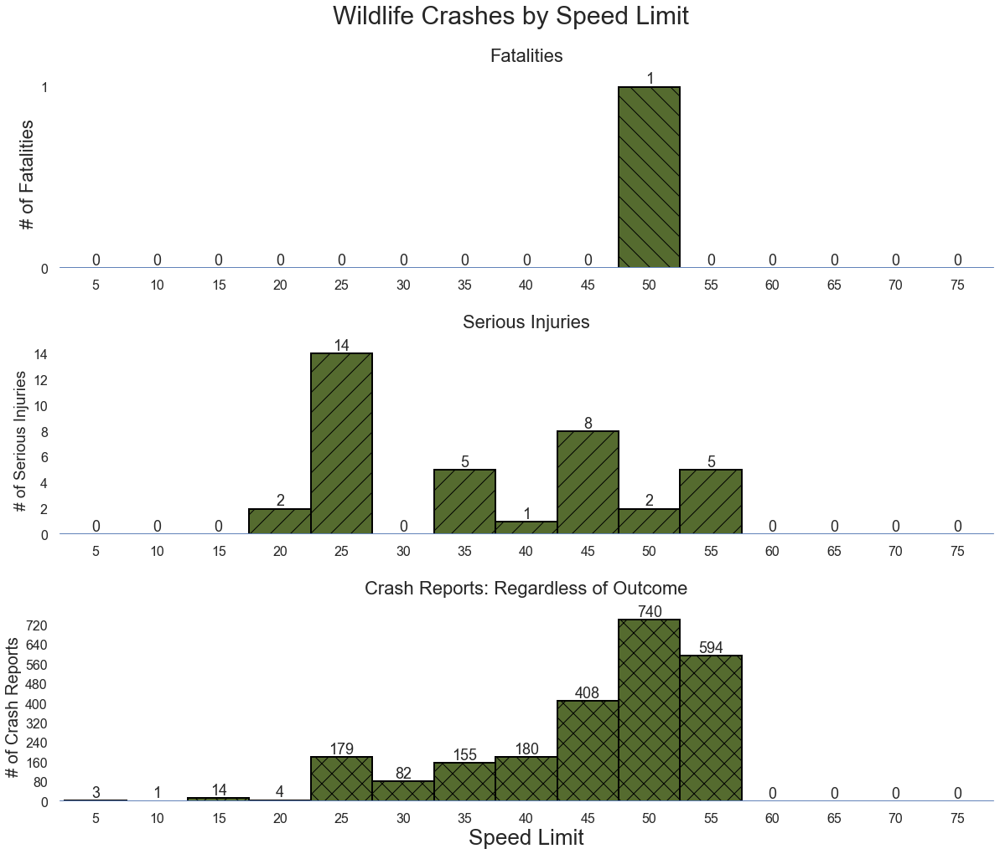

In [29]:
# test figure; once satisfied, run all seven to save separately from companion document
create_posted_speed_fig_animals("NCR")

### Table 5: Wildlife Crash Outcomes by Park

In [30]:
def create_wildlife_crashes_table_park(region):
    # create dataframe for number of serious injuries and fatalities in wildlife crashes, number of wildlife crashes that resulted in an injury or fatality by park   
    region = analysis_2022.loc[analysis_2022['RGN']==region]
    animal_region = region.loc[region['Involving Animal']==1]
    animal_region_slim = animal_region[['Park', 'Num_Fatalities', 'Incapacitating Injury', 'Injury or Fatal']]
    animal_region_parks = animal_region_slim.groupby(by=['Park'], as_index=False).sum()
    animal_region_parks['Number of Fatalities'] = animal_region_parks['Num_Fatalities'].astype(int)
    animal_region_parks['Number of Serious Injuries'] = animal_region_parks['Incapacitating Injury'].astype(int)
    animal_region_parks['Number of Crashes Resulting in an Injury or Fatality'] = animal_region_parks['Injury or Fatal'].astype(int)
    animal_region_parks = animal_region_parks.drop(columns={'Num_Fatalities','Num_Fatalities', 'Incapacitating Injury', 'Injury or Fatal'})
    animal_region_parks = animal_region_parks.sort_values(by = ["Number of Fatalities","Number of Serious Injuries","Number of Crashes Resulting in an Injury or Fatality"], ascending = False)


    return animal_region_parks

In [31]:
def make_wildlife_crashes_table_park(region):
    df = create_wildlife_crashes_table_park(region)
    doc_name = './22-23/Drafted Deliverables/NPS TSP Regional Briefing Draft 22-23 - blank.docx' # start with blank Volpe template
    doc = docx.Document(doc_name)
    doc.add_heading("Park-Level Wildlife Crashes and Outcomes")
    t = doc.add_table(df.shape[0]+1, df.shape[1], style="Grid Table 5 Dark Accent 1") # blue alternating

    for j in range(df.shape[-1]):
        t.cell(0,j).text = df.columns[j]

    for i in range(df.shape[0]):
        for j in range(df.shape[-1]):
            t.cell(i+1,j).text = str(df.values[i,j])
    doc_name_new = './22-23\Drafted Deliverables\Figures/Wildlife Tables/' 'Park-Level-' + region + ".docx"
    doc.save(doc_name_new)

In [32]:
# test table; once satisfied, run all seven to save separately from companion document
make_wildlife_crashes_table_park("IMR")

### Table 6: Wildlife Crash Outcomes by Type of Animal

In [33]:
def create_wildlife_crashes_table_species(region):
    # create dataframe for number of serious injuries and fatalities in wildlife crashes, number of wildlife crashes that resulted in an injury or fatality by animal type
    animal = analysis_2022.loc[analysis_2022['Involving Animal']==1]
    animal_region = animal.loc[animal['RGN']==region]
    animal_region_inj_or_fatal = animal_region.loc[animal_region['Injury or Fatal']==1]
    animal_list = ['HorseLlama', 'Cow', 'Deer', 'Elk', 'Moose', 'Buffalo', 'Bear', 'Antelope', 'SheepGoats', 'OtherWild', 'OtherDomestic']
    df_final = pd.DataFrame(columns={"Type of Animal", "Number of Fatalities", "Number of Serious Injuries", 'Number of Crashes Resulting in an Injury or Fatality'})
    animal_fatalities = []
    animal_serious_injuries = []
    animal_inj_or_fatal_crashes = []

    for i in animal_list:
        num_animal_fatalities = int(animal_region.loc[animal_region[i]==1]['Num_Fatalities'].sum())
        animal_fatalities.append(num_animal_fatalities)
        num_animal_serious_injuries = int(animal_region.loc[animal_region[i]==1]['Incapacitating Injury'].sum())
        animal_serious_injuries.append(num_animal_serious_injuries)    
        animal_inj_or_fatal_num_crashes = int(animal_region_inj_or_fatal.loc[animal_region_inj_or_fatal[i]==1].shape[0])
        animal_inj_or_fatal_crashes.append(animal_inj_or_fatal_num_crashes)

    df_final["Number of Fatalities"] = animal_fatalities
    df_final["Number of Serious Injuries"] = animal_serious_injuries
    df_final["Number of Crashes Resulting in an Injury or Fatality"] = animal_inj_or_fatal_crashes
    df_final["Type of Animal"] = ['Horse/Llama', 'Cow', 'Deer', 'Elk', 'Moose', 'Buffalo', 'Bear', 'Antelope', 'Sheep/Goat', 'Other Wild Animal', 'Other Domestic Animal']
    df_final = df_final[["Type of Animal","Number of Fatalities","Number of Serious Injuries","Number of Crashes Resulting in an Injury or Fatality"]]
    
    return df_final

In [34]:
def make_wildlife_crashes_table_species(region):
    df = create_wildlife_crashes_table_species(region)
    doc_name = './22-23/Drafted Deliverables/NPS TSP Regional Briefing Draft 22-23 - blank.docx' # start with blank Volpe template
    doc = docx.Document(doc_name)
    doc.add_heading("Species-Level Wildlife Crashes and Outcomes")
    t = doc.add_table(df.shape[0]+1, df.shape[1], style="Grid Table 5 Dark Accent 6") # green alternating

    for j in range(df.shape[-1]):
        t.cell(0,j).text = df.columns[j]

    for i in range(df.shape[0]):
        for j in range(df.shape[-1]):
            t.cell(i+1,j).text = str(df.values[i,j])
    doc_name_new = './22-23\Drafted Deliverables\Figures/Wildlife Tables/' 'Species-Level-' + region + ".docx"
    doc.save(doc_name_new)

In [35]:
# test table; once satisfied, run all seven to save separately from companion document
make_wildlife_crashes_table_species("NCR")

## Data Quality Tables

### Table 7: CDS Data Completeness, Regional and National

In [36]:
# load database created to include all crash IDs from CDS that can be attributed to a region
cds_all = pd.read_csv(".//Data//Output Data//CDS_slim_clean_forChris.csv") 

In [37]:
def create_data_quality_table_cds(region):
    cds_all_region = cds_all.loc[cds_all['RGN']==region]
    cds_total_crashes = cds_all.shape[0]
    cds_region_crashes = cds_all_region.shape[0]
    cds_total_unlinked = round(cds_all.loc[cds_all['5_mph'].isnull()==True].shape[0]/cds_total_crashes*100,1)
    cds_region_unlinked = round(cds_all_region.loc[cds_all_region['5_mph'].isnull()==True].shape[0]/cds_region_crashes*100,1)
    cds_total_missingcords = round(cds_all.loc[cds_all['LATITUDE'].isnull()==True].shape[0]/cds_total_crashes*100,1)
    cds_region_missingcords = round(cds_all_region.loc[cds_all_region['LATITUDE'].isnull()==True].shape[0]/cds_region_crashes*100,1)
    
    final_df = pd.DataFrame({
        "Area":["National", region],
        'Total Number of Crashes': [cds_total_crashes, cds_region_crashes], 
        "Unlinked Percentage": [str(cds_total_unlinked) + "%", str(cds_region_unlinked) + "%"],
        "Missing Coordinates Percentage": [str(cds_total_missingcords) + "%", str(cds_region_missingcords) + "%"]
    })
    
    return final_df

In [38]:
def make_data_quality_table_cds(region):
    df = create_data_quality_table_cds(region)
    doc_name = './22-23/Drafted Deliverables/NPS TSP Regional Briefing Draft 22-23 - blank.docx' # start wtih blank Volpe template
    doc = docx.Document(doc_name)
    doc.add_heading("CDS Data Quality, Regional and National")
    t = doc.add_table(df.shape[0]+1, df.shape[1], style="Grid Table 5 Dark Accent 1") # blue alternating

    for j in range(df.shape[-1]):
        t.cell(0,j).text = df.columns[j]

    for i in range(df.shape[0]):
        for j in range(df.shape[-1]):
            t.cell(i+1,j).text = str(df.values[i,j])
            
    doc_name_new = './22-23\Drafted Deliverables\Figures/Data Quality Tables\CDS-' + region + ".docx"
    doc.save(doc_name_new)

In [39]:
# test table; once satisfied, run all seven to save separately from companion document
make_data_quality_table_cds("NCR")

### Table 8: IMARS Data Completeness, Regional and National

In [40]:
# load database created to include all crash IDs from IMARS that can be attributed to a region
imars_all = pd.read_csv(".//Data//Output Data//IMARS_slim_clean_forChris.csv") 

In [41]:
imars_all.shape

(12790, 53)

In [42]:
def create_data_quality_table_imars(region):
    imars_all_region = imars_all.loc[imars_all['RGN']==region]
    imars_total_crashes = imars_all.shape[0]
    imars_region_crashes = imars_all_region.shape[0]
    imars_total_unlinked = round(imars_all.loc[imars_all['5_mph'].isnull()==True].shape[0]/imars_total_crashes*100,1)
    imars_region_unlinked = round(imars_all_region.loc[imars_all_region['5_mph'].isnull()==True].shape[0]/imars_region_crashes*100,1)
    imars_total_missingcords = round(imars_all.loc[imars_all['LATITUDE'].isnull()==True].shape[0]/imars_total_crashes*100,1)
    imars_region_missingcords = round(imars_all_region.loc[imars_all_region['LATITUDE'].isnull()==True].shape[0]/imars_region_crashes*100,1)
    
    final_df = pd.DataFrame({
        "Area":["National", region],
        'Total Number of Crashes': [imars_total_crashes, imars_region_crashes], 
        "Unlinked Percentage": [str(imars_total_unlinked) + "%", str(imars_region_unlinked) + "%"],
        "Missing Coordinates Percentage": [str(imars_total_missingcords) + "%", str(imars_region_missingcords) + "%"]
    })
    
    return final_df

In [43]:
def make_data_quality_table_imars(region):
    df = create_data_quality_table_imars(region)
    doc_name = './22-23/Drafted Deliverables/NPS TSP Regional Briefing Draft 22-23 - blank.docx' # start wtih blank Volpe template
    doc = docx.Document(doc_name)
    doc.add_heading("IMARS Data Quality, Regional and National")
    t = doc.add_table(df.shape[0]+1, df.shape[1], style="Grid Table 5 Dark Accent 6") # green alternating

    for j in range(df.shape[-1]):
        t.cell(0,j).text = df.columns[j]

    for i in range(df.shape[0]):
        for j in range(df.shape[-1]):
            t.cell(i+1,j).text = str(df.values[i,j])
            
    doc_name_new = './22-23\Drafted Deliverables\Figures/Data Quality Tables\IMARS-' + region + ".docx"
    doc.save(doc_name_new)

In [44]:
# test table; once satisfied, run all seven to save separately from companion document
make_data_quality_table_imars("NCR")

## Yearly count of crashes by database

### Figures 4 and 5. Annual Regional Serious Injuries/Fatalities by Data System and Georeference Quality

In [45]:
def make_yearly_crash_fig(region):
    
    # set up dataframes for plotting
    df = analysis_2022.loc[analysis_2022['RGN']==region]
    df['ones'] = 1
    df_year_origin=df.groupby(['database', "CRASH_YEAR"]).sum()
    df_year_origin=df_year_origin.reset_index()
    df_year_origin = df_year_origin.loc[df_year_origin['CRASH_YEAR']<2022]
    df_year_origin = df_year_origin.loc[df_year_origin['CRASH_YEAR']>1988]

    df_year_origin_coords = df.loc[df['LATITUDE'].notnull()]
    df_year_origin_coords = df_year_origin_coords.groupby(['database', "CRASH_YEAR"]).sum()
    df_year_origin_coords=df_year_origin_coords.reset_index()
    df_year_origin_coords = df_year_origin_coords.loc[df_year_origin_coords['CRASH_YEAR']<2022]
    df_year_origin_coords = df_year_origin_coords.loc[df_year_origin_coords['CRASH_YEAR']>1988]
    
    cds_year = df_year_origin.loc[df_year_origin['database']=='CDS']
    imars_year = df_year_origin.loc[df_year_origin['database']=='IMARS']
    cds_year_coords = df_year_origin_coords.loc[df_year_origin_coords['database']=='CDS']
    imars_year_coords = df_year_origin_coords.loc[df_year_origin_coords['database']=='IMARS']
    
    # plot fig 1 for Serious Injuries
    plt.style.use('seaborn')
    tick_spacing = 2 
    sns.set(rc={'axes.facecolor':'1', 'figure.facecolor':'white', 'patch.linewidth': 0.0})
    fig,ax = plt.subplots(1,1, figsize=(14, 7))

    ax.set_title('Annual Regional Serious Injuries by Data System and Georeference Quality', fontsize=20)
    ax.fill_between(cds_year["CRASH_YEAR"], cds_year['Incapacitating Injury'], label = 'CDS', 
#       hatch = ".", 
                    facecolor = "steelblue")
    ax.fill_between(cds_year_coords["CRASH_YEAR"], cds_year_coords['Incapacitating Injury'], label = 'CDS with lat/long coordinates', 
       hatch = '/', facecolor = "skyblue")
    ax.fill_between(imars_year["CRASH_YEAR"], imars_year['Incapacitating Injury'], label = 'IMARS', 
#       hatch = "/", 
                    facecolor = "orangered")
    ax.fill_between(imars_year_coords["CRASH_YEAR"], imars_year_coords['Incapacitating Injury'], label = 'IMARS with lat/long coordinates', 
        hatch = "/", facecolor = "darksalmon")
    
    legend = plt.legend(frameon = 2,fontsize=20)
    frame = legend.get_frame()
    frame.set_color('white')
    frame.set_facecolor('white')
    frame.set_edgecolor('black')
    plt.xlim([1990,2021])
    #ymax = round(max(cds_year['Incapacitating Injury']),-3)
    #plt.ylim([0,ymax])
    #ax.set_yticks([0,100,200,300,400,500,600,700])
    ax.grid('off')
    ax.xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
    ax.tick_params(axis='x', which='major', labelsize=23, rotation=45)
    ax.tick_params(axis='y', which='major', labelsize=23)
    ax.tick_params(axis='both', which='minor', labelsize=23)
    ax.hlines(0, xmin = 1990, xmax = 2021, linewidth = 1, color = "grey")
    ax.set_xlabel("Year", fontsize=26)
    ax.set_ylabel("Number of Serious Injuries", fontsize=26)
    
    doc_name = './22-23\Drafted Deliverables\Figures/Data Quality Tables/' 'serious injury-'+ region + ".png"
    
    plt.savefig(doc_name)

    # plot fig 2 for Fatalities
    plt.style.use('seaborn')
    tick_spacing = 2 
    sns.set(rc={'axes.facecolor':'1', 'figure.facecolor':'white', 'patch.linewidth': 0.0})
    fig,ax = plt.subplots(1,1, figsize=(14, 7))

    ax.set_title('Annual Regional Fatalities by Data System and Georeference Quality', fontsize=20)
    ax.fill_between(cds_year["CRASH_YEAR"], cds_year['Num_Fatalities'], label = 'CDS', 
#       hatch = ".", 
                    facecolor = "steelblue")
    ax.fill_between(cds_year_coords["CRASH_YEAR"], cds_year_coords['Num_Fatalities'], label = 'CDS with lat/long coordinates', 
       hatch = '/', facecolor = "skyblue")
    ax.fill_between(imars_year["CRASH_YEAR"], imars_year['Num_Fatalities'], label = 'IMARS', 
#       hatch = "/", 
                    facecolor = "orangered")
    ax.fill_between(imars_year_coords["CRASH_YEAR"], imars_year_coords['Num_Fatalities'], label = 'IMARS with lat/long coordinates', 
        hatch = "/", 
                    facecolor = "darksalmon")

    legend = plt.legend(frameon = 2,fontsize=20)
    frame = legend.get_frame()
    frame.set_color('white')
    frame.set_facecolor('white')
    frame.set_edgecolor('black')
    plt.xlim([1990,2021])
    #ymax = round(max(cds_year['Num_Fatalities']),-1)
    #plt.ylim([0,ymax])
    #ax.set_yticks([0,10,20,30,40,50,60,70,80])
    ax.grid('off')
    ax.xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
    ax.tick_params(axis='x', which='major', labelsize=23, rotation=45)
    ax.tick_params(axis='y', which='major', labelsize=23)
    ax.tick_params(axis='both', which='minor', labelsize=23)
    ax.hlines(0, xmin = 1990, xmax = 2021, linewidth = 1, color = "grey")
    ax.set_xlabel("Year", fontsize=26)
    ax.set_ylabel("Number of Fatalities", fontsize=26)
    
    doc_name = './22-23\Drafted Deliverables\Figures/Data Quality Tables/' 'fatality-' + region + ".png"
    plt.savefig(doc_name)
    

<ipython-input-45-614f1c3e4d02>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['ones'] = 1


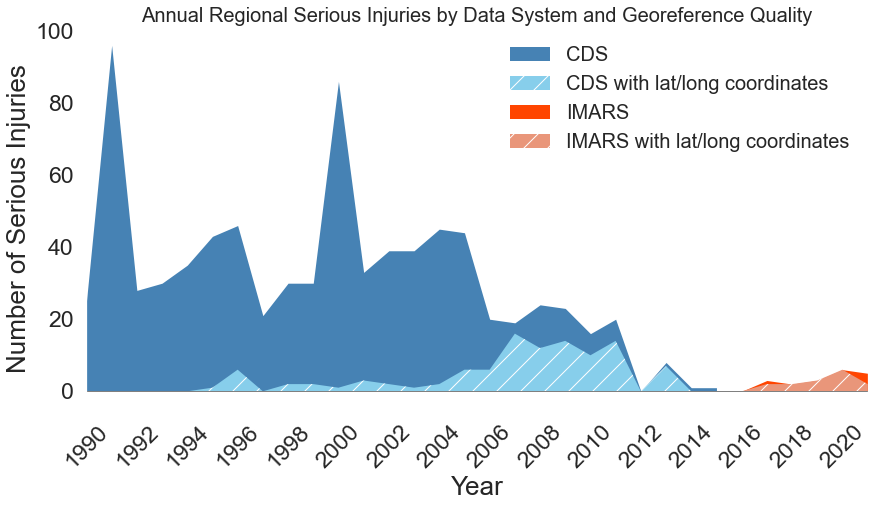

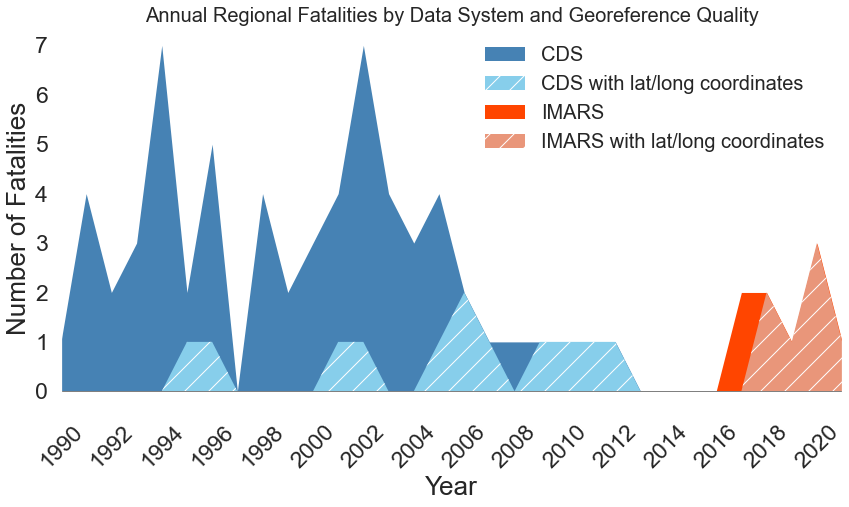

In [46]:
# test figures; once satisfied, run all seven to save separately from companion document
make_yearly_crash_fig("NER")

## IMARS geolocation quality assessment for top 10 parks

### Figure 6: IMARS Lat/Long Distance from Park Boundary for Top 10 Parks

In [47]:
def make_coordinate_bin_fig(region):
    
    # set up dataframes for plotting
    df = pd.read_excel(".//Data//Output Data//Final Coordinate Stats No AKR.xlsx")
    df.columns=["Park","Region","Within Boundary","<1mi Out","1-10mi Out","10-100mi Out",">100mi Out","No Coordinates","Total Crashes"]
    df_region = df.loc[df['Region']==region]
    df_region = df_region.sort_values(by="Total Crashes", ascending=False)
    top10 = pd.DataFrame(df_region.head(10)) # 10 parks with the most crashes in the region
    
    # determine proportion of total crashes for plotting 100% stacked bars
    top10['Within Boundary'] = top10['Within Boundary']/top10['Total Crashes']
    top10["<1mi Out"] = top10["<1mi Out"]/top10['Total Crashes']
    top10["1-10mi Out"] = top10["1-10mi Out"]/top10['Total Crashes']
    top10["10-100mi Out"] = top10["10-100mi Out"]/top10['Total Crashes']
    top10[">100mi Out"] = top10[">100mi Out"]/top10['Total Crashes']
    top10["No Coordinates"] = top10["No Coordinates"]/top10['Total Crashes']
    top10_slim = top10.drop(columns=['Park','Region','Total Crashes'])
    
    # begin plotting
    # Each column will take the sum of all columns before it as its base
    bottom_list = []

    for i in top10_slim.columns:
        b = list(top10_slim.loc[:, top10_slim.columns[0]: i].sum(axis=1))
        bottom_list.append(b)

    fig,ax = plt.subplots(1,1, figsize=(17, 7))
    x_ax = top10['Park']

    patterns = ['','/','','/','','/'] # define hatch for each bin
  #  patterns = ['.','o','O','*','//','\\'] # define hatch for each bin
    colorlist = ['forestgreen','mistyrose', 'lightcoral', 'firebrick', 'maroon', 'slategrey'] # define color for each bin
    for i, v in enumerate(top10_slim.columns):
        if i == 0:
            # First column is at the bottom of the chart so bottom is 0 and doesn't need to be specified.
            ax.bar(x_ax, top10_slim[v], hatch=patterns[i], color=colorlist[i], edgecolor='k')
        else:
            ax.bar(x_ax, top10_slim[v], bottom=bottom_list[i - 1], hatch=patterns[i], color=colorlist[i], edgecolor='k')
    
    ax.tick_params(axis='x', which='major', labelsize=15)
    y_vals = ax.get_yticks()
    ax.set_yticklabels(['{:.0%}'.format(y) for y in y_vals], fontsize=15)
    ax.set_ylabel("Percent of Total IMARS Crashes", fontsize=18)
    ax.set_xlabel("Park", fontsize=18)
    ax.axhline(y=0, color='k')
    
    within_patch = mpatches.Patch(hatch=patterns[0], facecolor=colorlist[0], edgecolor="black", label=top10_slim.columns[0])
    one_mile_patch = mpatches.Patch(hatch=patterns[1], facecolor=colorlist[1], edgecolor="black", label=top10_slim.columns[1])
    ten_mile_patch = mpatches.Patch(hatch=patterns[2], facecolor=colorlist[2], edgecolor="black", label=top10_slim.columns[2])
    hundred_mile_patch = mpatches.Patch(hatch=patterns[3], facecolor=colorlist[3], edgecolor="black", label=top10_slim.columns[3])
    over_hundred_mile_patch = mpatches.Patch(hatch=patterns[4], facecolor=colorlist[4], edgecolor="black", label=top10_slim.columns[4])
    no_coords_patch = mpatches.Patch(hatch=patterns[5], facecolor=colorlist[5], edgecolor="black", label=top10_slim.columns[5])
    ax.legend(loc="upper left", frameon=1,bbox_to_anchor=(0.95, 1), prop={'size': 15}, handles = [within_patch, one_mile_patch, ten_mile_patch, hundred_mile_patch, over_hundred_mile_patch, no_coords_patch])
    ax.set_title('IMARS Lat/Long Distance from Park Boundary for Top 10 Parks', fontsize=22, pad = 20)
    
    doc_name = './22-23\Drafted Deliverables\Figures/IMARS Coordinate Geolocation Figures/' + region + ".png"
    
    plt.savefig(doc_name)    

In [ ]:
df = pd.read_excel(".//Data//Output Data//Final Coordinate Stats No AKR.xlsx")
df.columns=["Park","Region","Within Boundary","<1mi Out","1-10mi Out","10-100mi Out",">100mi Out","No Coordinates","Total Crashes"]
df_region = df.loc[df['Region']=='NCR']
df_region = df_region.sort_values(by="Total Crashes", ascending=False)
top10 = pd.DataFrame(df_region.head(10)) # 10 parks with the most crashes in the region
    
    # determine proportion of total crashes for plotting 100% stacked bars
top10['Within Boundary'] = top10['Within Boundary']/top10['Total Crashes']
top10["<1mi Out"] = top10["<1mi Out"]/top10['Total Crashes']
top10["1-10mi Out"] = top10["1-10mi Out"]/top10['Total Crashes']
top10["10-100mi Out"] = top10["10-100mi Out"]/top10['Total Crashes']
top10[">100mi Out"] = top10[">100mi Out"]/top10['Total Crashes']
top10["No Coordinates"] = top10["No Coordinates"]/top10['Total Crashes']
top10

<ipython-input-47-e0601b3aa529>:42: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(['{:.0%}'.format(y) for y in y_vals], fontsize=15)


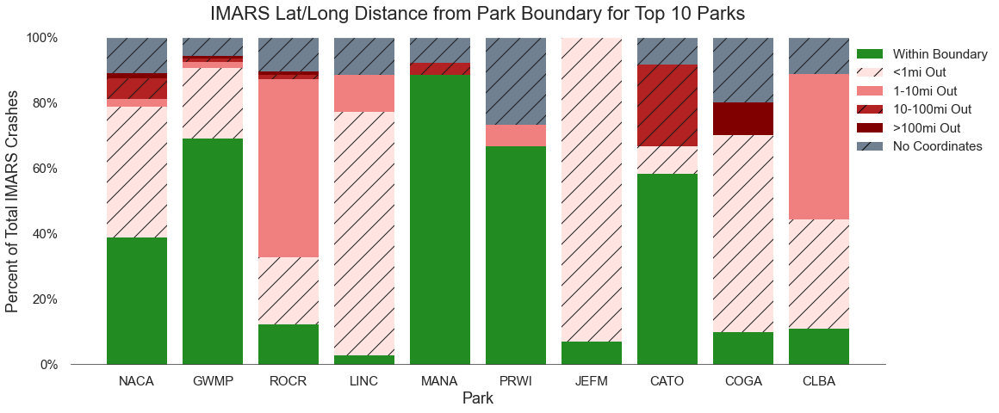

In [48]:
# test figures; once satisfied, run all seven to save separately from companion document
make_coordinate_bin_fig("NCR")

# Wishlist

## VRU crashes

### Table 9: Crashes Involving VRUs, Regional and National 

In [49]:
def create_vru_crashes_table(region):
    # create dataframe for % of total crashes involving VRUs, % of VRU crashes resulting in an injury or fatality, serious injuries and fatalities in VRU crashes   

    rgn = analysis_2022.loc[analysis_2022['RGN']==region]
    vru = analysis_2022.loc[analysis_2022['VRU']==1]
    vru_inj_or_fatal = vru.loc[vru['Injury or Fatal']==1]
    vru_region = vru.loc[vru['RGN']==region]
    vru_inj_or_fatal_region = vru_region.loc[vru_region['Injury or Fatal']==1]
    #vru_total_crashes_region = vru_inj_or_fatal_region.shape[0]
    vru_percent_region = round(vru_region.shape[0]/rgn.shape[0]*100,2)
    vru_inj_or_fatal_percent_region = round(vru_inj_or_fatal_region.shape[0]/vru_region.shape[0]*100,2)
    #vru_injury_region = int(vru_region['Num_Injuries'].sum())
    vru_serious_injury_region = int(vru_region['Incapacitating Injury'].sum())
    vru_fatals_region = int(vru_region['Num_Fatalities'].sum())
        
    #vru_total_crashes = vru_inj_or_fatal.shape[0]
    vru_percent = round(vru.shape[0]/analysis_2022.shape[0]*100,2)
    vru_inj_or_fatal_percent = round(vru_inj_or_fatal.shape[0]/vru.shape[0]*100,2)
    #vru_injury = int(vru['Num_Injuries'].sum())
    vru_serious_injury = int(vru['Incapacitating Injury'].sum())
    vru_fatals = int(vru['Num_Fatalities'].sum())
    
    df_final = pd.DataFrame({
    "Fields": ["Percent of Total Crashes", "Percent of VRU Crashes that Resulted in an Injury/Fatality", "Number of Serious Injuries", "Number of Fatalities"],
    region: [str(vru_percent_region) + "%", str(vru_inj_or_fatal_percent_region) + "%", vru_serious_injury_region, vru_fatals_region], 
    "National": [str(vru_percent) + "%", str(vru_inj_or_fatal_percent) + "%", vru_serious_injury, vru_fatals]
     })
    
    return df_final

In [50]:
def make_vru_crashes_table(region):
    df = create_vru_crashes_table(region)
    doc_name = './22-23/Drafted Deliverables/NPS TSP Regional Briefing Draft 22-23 - blank.docx' # start with blank Volpe template
    doc = docx.Document(doc_name)
    doc.add_heading("Crashes Involving VRUs, Regional and National")
    t = doc.add_table(df.shape[0]+1, df.shape[1], style="Grid Table 5 Dark Accent 1") # blue alternating

    for j in range(df.shape[-1]):
        t.cell(0,j).text = df.columns[j]

    for i in range(df.shape[0]):
        for j in range(df.shape[-1]):
            t.cell(i+1,j).text = str(df.values[i,j])
    doc_name_new = './22-23\Drafted Deliverables\Figures/VRU tables/' + region + ".docx"
    doc.save(doc_name_new)

In [51]:
# test table; once satisfied, run all seven to save separately from companion document
make_vru_crashes_table("NCR")

### Table 10: VRU Crash Outcomes by Park

In [52]:
def create_vru_crashes_table_park(region):
    # create dataframe for number of serious injuries and fatalities in VRU crashes, number of VRU crashes that resulted in an injury or fatality by park   
    region = analysis_2022.loc[analysis_2022['RGN']==region]
    vru_region = region.loc[region['VRU']==1]
    vru_region_slim = vru_region[['Park', 'Num_Fatalities', 'Incapacitating Injury', 'Injury or Fatal']]
    vru_region_parks = vru_region_slim.groupby(by=['Park'], as_index=False).sum()
    vru_region_parks['Number of Fatalities'] = vru_region_parks['Num_Fatalities'].astype(int)
    vru_region_parks['Number of Serious Injuries'] = vru_region_parks['Incapacitating Injury'].astype(int)
    vru_region_parks['Number of Crashes Resulting in an Injury or Fatality'] = vru_region_parks['Injury or Fatal'].astype(int)
    vru_region_parks = vru_region_parks.drop(columns={'Num_Fatalities','Num_Fatalities', 'Incapacitating Injury', 'Injury or Fatal'})
    vru_region_parks = vru_region_parks.sort_values(by = ["Number of Fatalities","Number of Serious Injuries","Number of Crashes Resulting in an Injury or Fatality"], ascending = False)


    return vru_region_parks

In [53]:
def make_vru_crashes_table_park(region):
    df = create_vru_crashes_table_park(region)
    doc_name = './22-23/Drafted Deliverables/NPS TSP Regional Briefing Draft 22-23 - blank.docx' # start with blank Volpe template
    doc = docx.Document(doc_name)
    doc.add_heading("Park-Level VRU Crashes and Outcomes")
    t = doc.add_table(df.shape[0]+1, df.shape[1], style="Grid Table 5 Dark Accent 6") # green alternating

    for j in range(df.shape[-1]):
        t.cell(0,j).text = df.columns[j]

    for i in range(df.shape[0]):
        for j in range(df.shape[-1]):
            t.cell(i+1,j).text = str(df.values[i,j])
    doc_name_new = './22-23\Drafted Deliverables\Figures/VRU Tables/' 'Park-Level-' + region + ".docx"
    doc.save(doc_name_new)

In [54]:
# test table; once satisfied, run all seven to save separately from companion document
make_vru_crashes_table_park("NCR")

### Figure 7: VRU crashes by Speed Limit

In [55]:
def create_posted_speed_fig_vrus(region):
    from matplotlib.ticker import MaxNLocator
    df = analysis_2022.loc[analysis_2022['RGN']==region]   
    speed_list = [5,10,15,20,25,30,35,40,45,50,55,60,65,70,75]
    speed_columns = ['5_mph', '10_mph', '15_mph', '20_mph', '25_mph','30_mph', '35_mph', '40_mph', '45_mph', '50_mph', '55_mph', '60_mph','65_mph', '70_mph', '75_mph']
    vru = df.loc[df['VRU']==1]
    vru_inj_or_fatal = vru.loc[vru['Injury or Fatal']==1]
    vru_fatalities = []
    vru_serious_injuries = []
    vru_crashes = []

    for i in speed_columns:
        num_vru_fatalities = vru.loc[vru[i]==1]['Num_Fatalities'].sum()
        vru_fatalities.append(num_vru_fatalities)
        num_vru_serious_injuries = vru.loc[vru[i]==1]['Incapacitating Injury'].sum()
        vru_serious_injuries.append(num_vru_serious_injuries)    
        num_vru_crashes = vru.loc[vru[i]==1].shape[0]
        #num_vru_crashes = vru_inj_or_fatal.loc[vru_inj_or_fatal[i]==1].shape[0]
        vru_crashes.append(num_vru_crashes)
        
    plt.style.use('seaborn')
    sns.set(rc={'axes.facecolor':'1', 'figure.facecolor':'white', 'patch.linewidth': 0.0})
    fig, ax = plt.subplots(3,1,figsize=(20,15))
    tick_spacing = 5
    fig.suptitle('VRU Crashes by Speed Limit', fontsize=30)

    # subplot data
    ax[0].bar(speed_list, vru_fatalities, width = 5, hatch = "\\", color = 'sienna', edgecolor = "black", linewidth=2)
    ax[1].bar(speed_list, vru_serious_injuries, width = 5, hatch = "/", color = 'sienna', edgecolor = "black", linewidth=2)
    ax[2].bar(speed_list, vru_crashes, width = 5, hatch = "x", color = 'sienna', edgecolor = "black", linewidth=2)

    # annotate all plots with bar totals
    rects = ax[0].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[0].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    rects = ax[1].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[1].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    rects = ax[2].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[2].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    # format each subplot
    ax[0].set_title("Fatalities",fontsize= 22, pad = 20)
    #ax[0].set_ylim([0, 20])
    ax[0].set_xlim([2, 78])
    ax[0].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
    ax[0].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
    ax[0].set_ylabel("# of Fatalities", fontsize = 22)#ylabel
    ax[0].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[0].tick_params(axis='x', which='major', labelsize=16)
    ax[0].tick_params(axis='y', which='major', labelsize=16)
    ax[0].tick_params(axis='both', which='minor', labelsize=8)

    ax[1].set_title("Serious Injuries",fontsize= 22, pad = 20)
    #ax[1].set_ylim([0, 200])
    ax[1].set_xlim([2, 78])
    ax[1].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
    ax[1].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
    ax[1].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[1].set_ylabel("# of Serious Injuries", fontsize = 19)#ylabel
    ax[1].tick_params(axis='x', which='major', labelsize=16)
    ax[1].tick_params(axis='y', which='major', labelsize=16)
    ax[1].tick_params(axis='both', which='minor', labelsize=8)

    ax[2].set_title("Crash Reports: Regardless of Outcome",fontsize= 22, pad = 20)
    #ax[2].set_ylim([0, 500])
    ax[2].set_xlim([2, 78])
    ax[2].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
    ax[2].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
    ax[2].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[2].set_xlabel('Speed Limit',fontsize = 26) #xlabel
    ax[2].set_ylabel("# of Crash Reports", fontsize = 20)#ylabel
    ax[2].tick_params(axis='x', which='major', labelsize=16)
    ax[2].tick_params(axis='y', which='major', labelsize=16)
    ax[2].tick_params(axis='both', which='minor', labelsize=8)

    # set the spacing between subplots
    plt.subplots_adjust(bottom=0.1, top=0.9, wspace=0.4, hspace=0.4)

    doc_name = './22-23\Drafted Deliverables\Figures/VRU Figures/' + region + ".png"
    
    plt.savefig(doc_name)


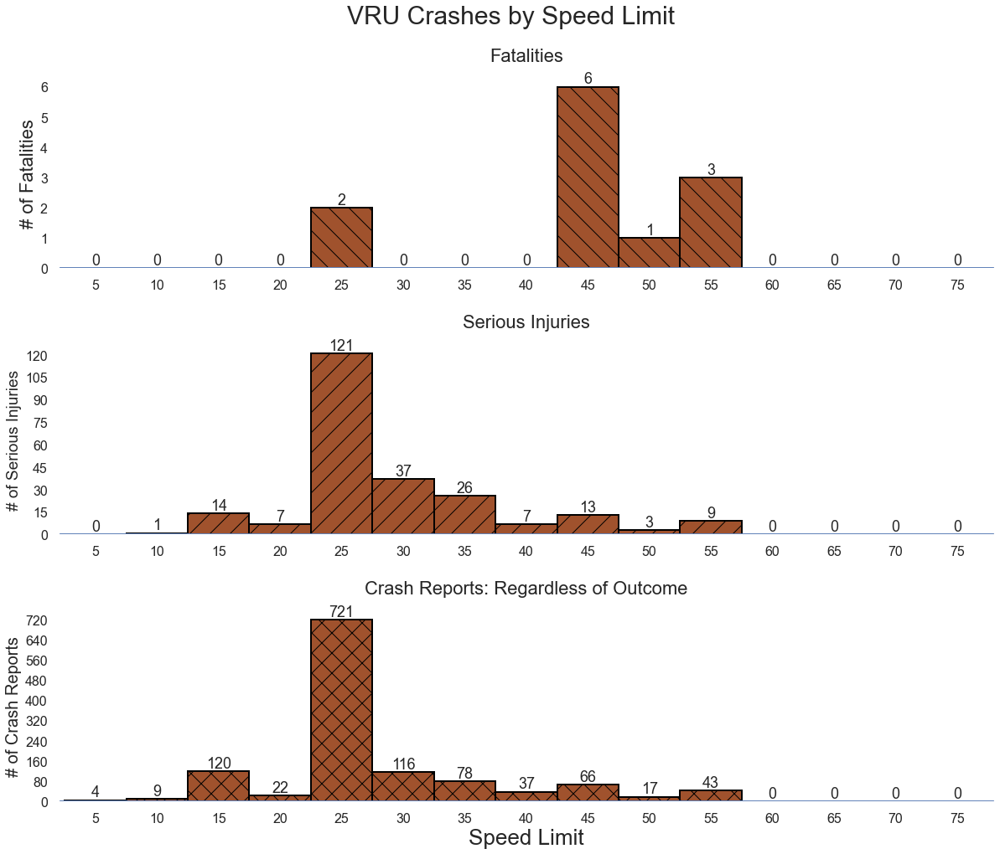

In [56]:
# test figure; once satisfied, run all seven to save separately from companion document
create_posted_speed_fig_vrus("NCR")

### Figure 8: VRU crashes by Location

In [57]:
def create_location_fig_vrus(region):
    from matplotlib.ticker import MaxNLocator
    df = analysis_2022.loc[analysis_2022['RGN']==region]   
    crosswalks = ['Crosswalk','Outside a Crosswalk']
    vru = df.loc[df['VRU']==1]
    vru_inj_or_fatal = vru.loc[vru['Injury or Fatal']==1]
    vru_crosswalk_fatalities = []
    vru_crosswalk_serious_injuries = []
    vru_crosswalk_crashes = []

    for i in crosswalks:
        num_vru_crosswalk_fatalities = vru.loc[vru[i]==1]['Num_Fatalities'].sum()
        vru_crosswalk_fatalities.append(num_vru_crosswalk_fatalities)
        num_vru_crosswalk_serious_injuries = vru.loc[vru[i]==1]['Incapacitating Injury'].sum()
        vru_crosswalk_serious_injuries.append(num_vru_crosswalk_serious_injuries)    
        num_vru_crosswalk_crashes = vru.loc[vru[i]==1].shape[0]
        #num_vru_crosswalk_crashes = vru_inj_or_fatal.loc[vru_inj_or_fatal[i]==1].shape[0]
        vru_crosswalk_crashes.append(num_vru_crosswalk_crashes)

    # set up main figure with three subplots
    plt.style.use('seaborn')
    sns.set(rc={'axes.facecolor':'1', 'figure.facecolor':'white', 'patch.linewidth': 0.0})
    fig, ax = plt.subplots(3,1,figsize=(20,15))
    fig.suptitle('VRU Crashes by Crash Location', fontsize=30)

    # subplot data
    ax[0].bar(crosswalks, vru_crosswalk_fatalities, hatch = "\\", color = 'sienna', edgecolor = "black", linewidth=2)
    ax[1].bar(crosswalks, vru_crosswalk_serious_injuries, hatch = "/", color = 'sienna', edgecolor = "black", linewidth=2)
    ax[2].bar(crosswalks, vru_crosswalk_crashes, hatch = "x", color = 'sienna', edgecolor = "black", linewidth=2)

    # annotate all plots with bar totals
    rects = ax[0].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[0].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    rects = ax[1].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[1].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    rects = ax[2].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[2].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    # format each subplot
    ax[0].set_title("Fatalities",fontsize= 22, pad = 20)
    #ax[0].set_ylim([0, 10])
    ax[0].hlines(0, xmin = 0, xmax = 1, linewidth = 3)
    ax[0].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[0].set_ylabel("# of Fatalities", fontsize = 22)#ylabel
    ax[0].tick_params(axis='x', which='major', labelsize=22)
    ax[0].tick_params(axis='y', which='major', labelsize=16)
    ax[0].tick_params(axis='both', which='minor', labelsize=8)

    ax[1].set_title("Serious Injuries",fontsize= 22, pad = 20)
    #ax[1].set_ylim([0, 100])
    ax[1].hlines(0, xmin = 0, xmax = 1, linewidth = 3)
    ax[1].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[1].set_ylabel("# of Serious Injuries", fontsize = 19)#ylabel
    ax[1].tick_params(axis='x', which='major', labelsize=22)
    ax[1].tick_params(axis='y', which='major', labelsize=16)
    ax[1].tick_params(axis='both', which='minor', labelsize=8)

    ax[2].set_title("Crash Reports: Regardless of Outcome",fontsize= 22, pad = 20)
    #ax[2].set_ylim([0, 250])
    ax[2].hlines(0, xmin = 0, xmax = 1, linewidth = 3)
    ax[2].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[2].set_xlabel('Crash Location',fontsize = 26) #xlabel
    ax[2].set_ylabel("# of Crash Reports", fontsize = 20)#ylabel
    ax[2].tick_params(axis='x', which='major', labelsize=22)
    ax[2].tick_params(axis='y', which='major', labelsize=16)
    ax[2].tick_params(axis='both', which='minor', labelsize=8)

    # set the spacing between subplots
    plt.subplots_adjust(bottom=0.1, top=0.9, wspace=0.4, hspace=0.4)

    doc_name = './22-23\Drafted Deliverables\Figures/Crosswalk Figures/' + region + ".png"
    
    plt.savefig(doc_name)


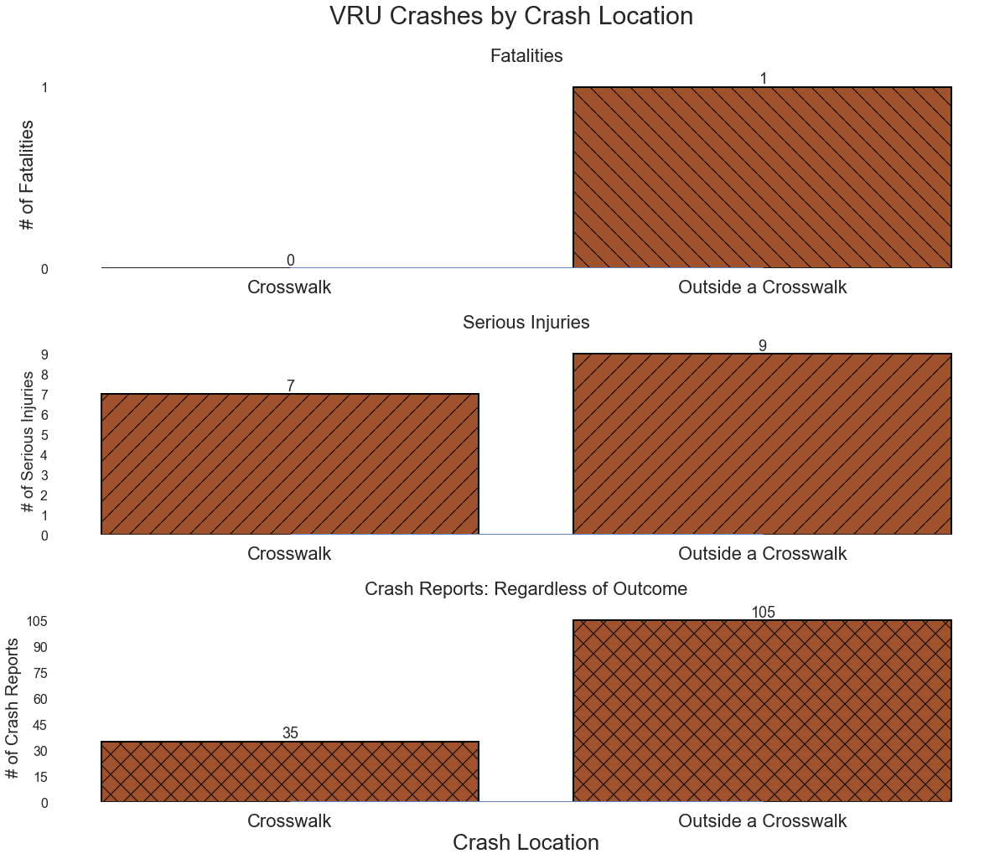

In [58]:
# test figure; once satisfied, run all seven to save separately from companion document
create_location_fig_vrus("NCR")

### Figure 9: VRU crashes by VRU Type

In [59]:
def create_type_fig_vrus(region):
    from matplotlib.ticker import MaxNLocator
    df = analysis_2022.loc[analysis_2022['RGN']==region]   
    vru_type = ['Pedestrian', 'Bicycle'] # pedacycle removed because all data were zero
    vru = df.loc[df['VRU']==1]
    vru_inj_or_fatal = vru.loc[vru['Injury or Fatal']==1]
    vru_type_fatalities = []
    vru_type_serious_injuries = []
    vru_type_crashes = []

    for i in vru_type:
        num_vru_type_fatalities = vru.loc[vru[i]==1]['Num_Fatalities'].sum()
        vru_type_fatalities.append(num_vru_type_fatalities)
        num_vru_type_serious_injuries = vru.loc[vru[i]==1]['Incapacitating Injury'].sum()
        vru_type_serious_injuries.append(num_vru_type_serious_injuries)    
        #num_vru_type_crashes = vru_inj_or_fatal.loc[vru_inj_or_fatal[i]==1].shape[0]
        num_vru_type_crashes = vru.loc[vru[i]==1].shape[0]
        vru_type_crashes.append(num_vru_type_crashes)

    # set up main figure with three subplots
    plt.style.use('seaborn')
    sns.set(rc={'axes.facecolor':'1', 'figure.facecolor':'white', 'patch.linewidth': 0.0})
    fig, ax = plt.subplots(3,1,figsize=(20,15))
    fig.suptitle('VRU Crashes by VRU Type', fontsize=30)

    # subplot data
    ax[0].bar(vru_type, vru_type_fatalities, hatch = "\\", color = 'sienna', edgecolor = "black", linewidth=2)
    ax[1].bar(vru_type, vru_type_serious_injuries, hatch = "/", color = 'sienna', edgecolor = "black", linewidth=2)
    ax[2].bar(vru_type, vru_type_crashes, hatch = "x", color = 'sienna', edgecolor = "black", linewidth=2)

    # annotate all plots with bar totals
    rects = ax[0].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[0].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    rects = ax[1].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[1].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    rects = ax[2].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[2].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    # format each subplot
    ax[0].set_title("Fatalities",fontsize= 22, pad = 20)
    #ax[0].set_ylim([0, 10])
    ax[0].hlines(0, xmin = 0, xmax = 1, linewidth = 3)
    ax[0].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[0].set_ylabel("# of Fatalities", fontsize = 22)#ylabel
    ax[0].tick_params(axis='x', which='major', labelsize=22)
    ax[0].tick_params(axis='y', which='major', labelsize=16)
    ax[0].tick_params(axis='both', which='minor', labelsize=8)

    ax[1].set_title("Serious Injuries",fontsize= 22, pad = 20)
    #ax[1].set_ylim([0, 100])
    ax[1].hlines(0, xmin = 0, xmax = 1, linewidth = 3)
    ax[1].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[1].set_ylabel("# of Serious Injuries", fontsize = 19)#ylabel
    ax[1].tick_params(axis='x', which='major', labelsize=22)
    ax[1].tick_params(axis='y', which='major', labelsize=16)
    ax[1].tick_params(axis='both', which='minor', labelsize=8)

    ax[2].set_title("Crash Reports: Regardless of Outcome",fontsize= 22, pad = 20)
    #ax[2].set_ylim([0, 250])
    ax[2].hlines(0, xmin = 0, xmax = 1, linewidth = 3)
    ax[2].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[2].set_xlabel('VRU Type',fontsize = 26) #xlabel
    ax[2].set_ylabel("# of Crash Reports", fontsize = 20)#ylabel
    ax[2].tick_params(axis='x', which='major', labelsize=22)
    ax[2].tick_params(axis='y', which='major', labelsize=16)
    ax[2].tick_params(axis='both', which='minor', labelsize=8)

    # set the spacing between subplots
    plt.subplots_adjust(bottom=0.1, top=0.9, wspace=0.4, hspace=0.4)

    doc_name = './22-23\Drafted Deliverables\Figures/VRU Figures/' 'VRU-types-'+ region + ".png"
    
    plt.savefig(doc_name)


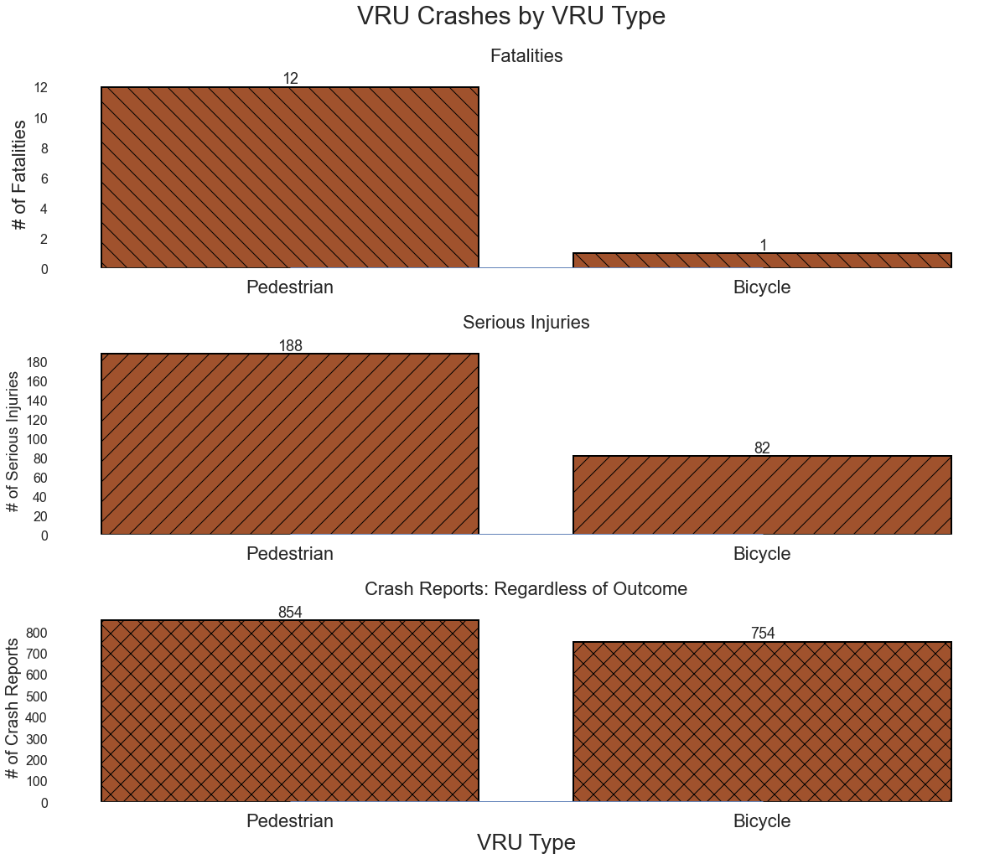

In [60]:
# test figure; once satisfied, run all seven to save separately from companion document
create_type_fig_vrus("NCR")

### Figure 10: VRU crashes by Speed Limit and VRU Type

In [61]:
def create_posted_speed_fig_vrus_type(region):
    from matplotlib.ticker import MaxNLocator
    import matplotlib.patches as mpatches
    df = analysis_2022.loc[analysis_2022['RGN']==region]   
    speed_list = [5,10,15,20,25,30,35,40,45,50,55,60,65,70,75]
    speed_ticks_1 = []
    speed_ticks_2 = []
    for i in speed_list:
        speedticks1 = i - 1.25
        speed_ticks_1.append(speedticks1)
        speedticks2 = i + 1.25
        speed_ticks_2.append(speedticks2)
    speed_columns = ['5_mph', '10_mph', '15_mph', '20_mph', '25_mph','30_mph', '35_mph', '40_mph', '45_mph', '50_mph', '55_mph', '60_mph','65_mph', '70_mph', '75_mph']
    vru = df.loc[df['VRU']==1]
    vru_inj_or_fatal = vru.loc[vru['Injury or Fatal']==1]
    peds = vru.loc[vru['Pedestrian']==1]
    bikes = vru.loc[vru['Bicycle']==1]
    ped_fatalities = []
    ped_serious_injuries = []
    ped_crashes = []
    bike_fatalities = []
    bike_serious_injuries = []
    bike_crashes = []

    for i in speed_columns:
        num_ped_fatalities = peds.loc[peds[i]==1]['Num_Fatalities'].sum()
        ped_fatalities.append(num_ped_fatalities)
        num_ped_serious_injuries = peds.loc[peds[i]==1]['Incapacitating Injury'].sum()
        ped_serious_injuries.append(num_ped_serious_injuries)    
        num_ped_crashes = peds.loc[peds[i]==1].shape[0]
        #num_ped_crashes = ped_inj_or_fatal.loc[ped_inj_or_fatal[i]==1].shape[0]
        ped_crashes.append(num_ped_crashes)
        num_bike_fatalities = bikes.loc[bikes[i]==1]['Num_Fatalities'].sum()
        bike_fatalities.append(num_bike_fatalities)
        num_bike_serious_injuries = bikes.loc[bikes[i]==1]['Incapacitating Injury'].sum()
        bike_serious_injuries.append(num_bike_serious_injuries)    
        num_bike_crashes = bikes.loc[bikes[i]==1].shape[0]
        #num_bike_crashes = bike_inj_or_fatal.loc[bike_inj_or_fatal[i]==1].shape[0]
        bike_crashes.append(num_bike_crashes)
        
    plt.style.use('seaborn')
    sns.set(rc={'axes.facecolor':'1', 'figure.facecolor':'white', 'patch.linewidth': 0.0})
    fig, ax = plt.subplots(3,1,figsize=(20,15))
    tick_spacing = 5
    fig.suptitle('VRU Crashes by Speed Limit and VRU Type', fontsize=30)

    # subplot data
    ax[0].bar(speed_ticks_1, ped_fatalities, width = 2.5, hatch = "|", color = 'chocolate', edgecolor = "black", linewidth=2, label='Pedestrian')
    ax[0].bar(speed_ticks_2, bike_fatalities, width = 2.5, hatch = "-", color = 'sandybrown', edgecolor = "black", linewidth=2, label='Bicycle')
    ax[1].bar(speed_ticks_1, ped_serious_injuries, width = 2.5, hatch = ".", color = 'chocolate', edgecolor = "black", linewidth=2, label='Pedestrian')
    ax[1].bar(speed_ticks_2, bike_serious_injuries, width = 2.5, hatch = "o", color = 'sandybrown', edgecolor = "black", linewidth=2, label='Bicycle')
    ax[2].bar(speed_ticks_1, ped_crashes, width = 2.5, hatch = "+", color = 'chocolate', edgecolor = "black", linewidth=2, label='Pedestrian')
    ax[2].bar(speed_ticks_2, bike_crashes, width = 2.5, hatch = "x", color = 'sandybrown', edgecolor = "black", linewidth=2, label='Bicycle')
    
    # annotate all plots with bar totals
    rects = ax[0].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[0].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    rects = ax[1].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[1].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    rects = ax[2].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[2].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    # format each subplot
    ax[0].set_title("Fatalities",fontsize= 22, pad = 20)
    #ax[0].set_ylim([0, 20])
    ax[0].set_xlim([2, 79])
    ax[0].hlines(0, xmin = 0, xmax = 79, linewidth = 3)
    ax[0].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
    ax[0].set_ylabel("# of Fatalities", fontsize = 22)#ylabel
    ax[0].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[0].tick_params(axis='x', which='major', labelsize=16)
    ax[0].tick_params(axis='y', which='major', labelsize=16)
    ax[0].tick_params(axis='both', which='minor', labelsize=8)
    
    ax[1].set_title("Serious Injuries",fontsize= 22, pad = 20)
    #ax[1].set_ylim([0, 200])
    ax[1].set_xlim([2, 79])
    ax[1].hlines(0, xmin = 0, xmax = 79, linewidth = 3)
    ax[1].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
    ax[1].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[1].set_ylabel("# of Serious Injuries", fontsize = 19)#ylabel
    ax[1].tick_params(axis='x', which='major', labelsize=16)
    ax[1].tick_params(axis='y', which='major', labelsize=16)
    ax[1].tick_params(axis='both', which='minor', labelsize=8)
    
    ax[2].set_title("Crash Reports: Regardless of Outcome",fontsize= 22, pad = 20)
    #ax[2].set_ylim([0, 500])
    ax[2].set_xlim([2, 79])
    ax[2].hlines(0, xmin = 0, xmax = 79, linewidth = 3)
    ax[2].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
    ax[2].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[2].set_xlabel('Speed Limit',fontsize = 26) #xlabel
    ax[2].set_ylabel("# of Crash Reports", fontsize = 20)#ylabel
    ax[2].tick_params(axis='x', which='major', labelsize=16)
    ax[2].tick_params(axis='y', which='major', labelsize=16)
    ax[2].tick_params(axis='both', which='minor', labelsize=8)
    
    # create legend for entire figure without hatching
    ped_patch = mpatches.Patch(color='chocolate', label='Pedestrian')
    bike_patch = mpatches.Patch(color='sandybrown', label='Bicycle')
    fig.legend(loc=1, prop={'size': 25}, handles = [ped_patch, bike_patch])

    # set the spacing between subplots
    plt.subplots_adjust(bottom=0.1, top=0.9, wspace=0.4, hspace=0.4)

    doc_name = './22-23\Drafted Deliverables\Figures/VRU Figures/' 'type_and_speed_' + region + ".png"
    
    plt.savefig(doc_name)


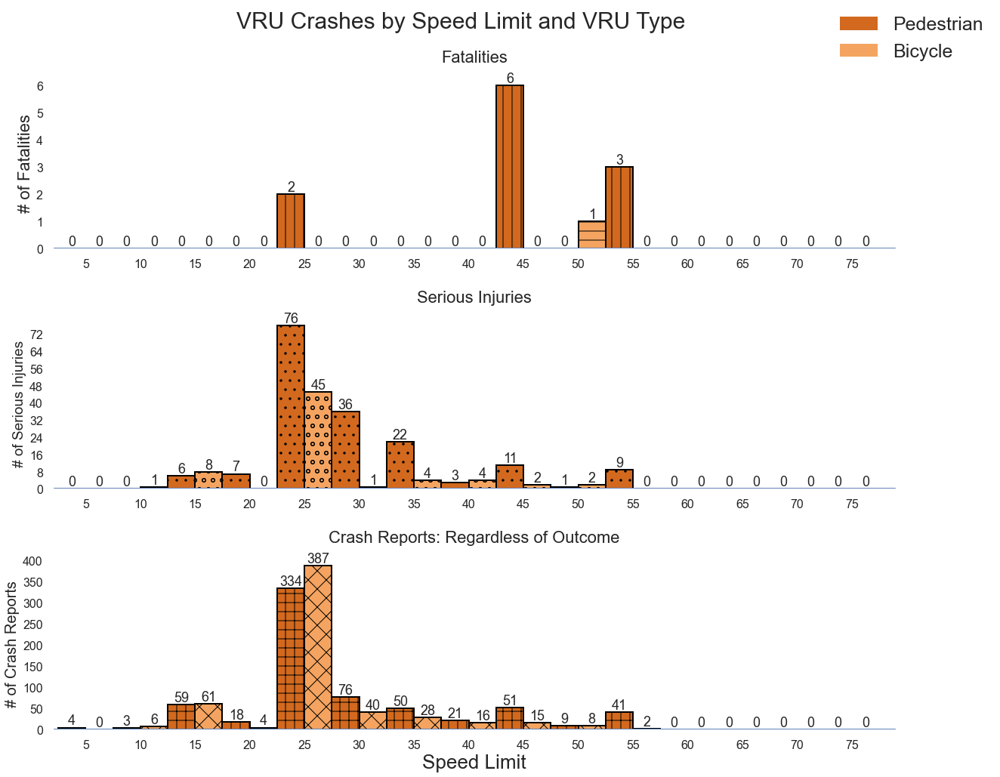

In [62]:
# test figure; once satisfied, run all seven to save separately from companion document
create_posted_speed_fig_vrus_type("NCR")

### Figure 11: VRU crashes by Location and VRU Type

In [63]:
def create_location_fig_vrus_type(region):
    from matplotlib.ticker import MaxNLocator
    import matplotlib.patches as mpatches
    df = analysis_2022.loc[analysis_2022['RGN']==region]   
    crosswalks = ['Crosswalk','Outside a Crosswalk']
    vru = df.loc[df['VRU']==1]
    vru_inj_or_fatal = vru.loc[vru['Injury or Fatal']==1]
    peds = vru.loc[vru['Pedestrian']==1]
    bikes = vru.loc[vru['Bicycle']==1]
    ped_crosswalk_fatalities = []
    ped_crosswalk_serious_injuries = []
    ped_crosswalk_crashes = []
    bike_crosswalk_fatalities = []
    bike_crosswalk_serious_injuries = []
    bike_crosswalk_crashes = []

    for i in crosswalks:
        num_ped_crosswalk_fatalities = peds.loc[peds[i]==1]['Num_Fatalities'].sum()
        ped_crosswalk_fatalities.append(num_ped_crosswalk_fatalities)
        num_ped_crosswalk_serious_injuries = peds.loc[peds[i]==1]['Incapacitating Injury'].sum()
        ped_crosswalk_serious_injuries.append(num_ped_crosswalk_serious_injuries)    
        num_ped_crosswalk_crashes = peds.loc[peds[i]==1].shape[0]
        #num_ped_crosswalk_crashes = peds_inj_or_fatal.loc[peds_inj_or_fatal[i]==1].shape[0]
        ped_crosswalk_crashes.append(num_ped_crosswalk_crashes)
        num_bike_crosswalk_fatalities = bikes.loc[bikes[i]==1]['Num_Fatalities'].sum()
        bike_crosswalk_fatalities.append(num_bike_crosswalk_fatalities)
        num_bike_crosswalk_serious_injuries = bikes.loc[bikes[i]==1]['Incapacitating Injury'].sum()
        bike_crosswalk_serious_injuries.append(num_bike_crosswalk_serious_injuries)    
        num_bike_crosswalk_crashes = bikes.loc[bikes[i]==1].shape[0]
        #num_bike_crosswalk_crashes = bikes_inj_or_fatal.loc[bikes_inj_or_fatal[i]==1].shape[0]
        bike_crosswalk_crashes.append(num_bike_crosswalk_crashes)

    # set up main figure with three subplots
    plt.style.use('seaborn')
    sns.set(rc={'axes.facecolor':'1', 'figure.facecolor':'white', 'patch.linewidth': 0.0})
    fig, ax = plt.subplots(3,1,figsize=(20,15))
    fig.suptitle('VRU Crashes by Crash Location and VRU Type', fontsize=30)

    # subplot data
    x1 = [0, 1.25]
    x2 = [0.5, 1.75]
    ax[0].bar(x1, ped_crosswalk_fatalities, width = 0.5, hatch = "|", color = 'chocolate', edgecolor = "black", linewidth=2, label='Pedestrian')
    ax[0].bar(x2, bike_crosswalk_fatalities, width = 0.5, hatch = "-", color = 'sandybrown', edgecolor = "black", linewidth=2, label='Bicycle')
    ax[1].bar(x1, ped_crosswalk_serious_injuries, width = 0.5, hatch = ".", color = 'chocolate', edgecolor = "black", linewidth=2, label='Pedestrian')
    ax[1].bar(x2, bike_crosswalk_serious_injuries, width = 0.5, hatch = "o", color = 'sandybrown', edgecolor = "black", linewidth=2, label='Bicycle')
    ax[2].bar(x1, ped_crosswalk_crashes, width = 0.5, hatch = "+", color = 'chocolate', edgecolor = "black", linewidth=2, label='Pedestrian')
    ax[2].bar(x2, bike_crosswalk_crashes, width = 0.5, hatch = "x", color = 'sandybrown', edgecolor = "black", linewidth=2, label='Bicycle')

    # annotate all plots with bar totals
    rects = ax[0].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[0].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    rects = ax[1].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[1].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    rects = ax[2].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[2].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    # format each subplot
    ax[0].set_title("Fatalities",fontsize= 22, pad = 20)
    #ax[0].set_ylim([0, 10])
    ax[0].hlines(0, xmin = 0, xmax = 1.5, linewidth = 3)
    ax[0].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[0].set_ylabel("# of Fatalities", fontsize = 22)#ylabel
    ax[0].tick_params(axis='x', which='major', labelsize=22)
    ax[0].set_xticks([0.25, 1.5])
    ax[0].set_xticklabels(crosswalks)
    ax[0].tick_params(axis='y', which='major', labelsize=16)
    ax[0].tick_params(axis='both', which='minor', labelsize=8)
    
    ax[1].set_title("Serious Injuries",fontsize= 22, pad = 20)
    #ax[1].set_ylim([0, 100])
    ax[1].hlines(0, xmin = 0, xmax = 1.5, linewidth = 3)
    ax[1].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[1].set_ylabel("# of Serious Injuries", fontsize = 19)#ylabel
    ax[1].tick_params(axis='x', which='major', labelsize=22)
    ax[1].set_xticks([0.25, 1.5])
    ax[1].set_xticklabels(crosswalks)
    ax[1].tick_params(axis='y', which='major', labelsize=16)
    ax[1].tick_params(axis='both', which='minor', labelsize=8)
    
    ax[2].set_title("Crash Reports: Regardless of Outcome",fontsize= 22, pad = 20)
    #ax[2].set_ylim([0, 250])
    ax[2].hlines(0, xmin = 0, xmax = 1.5, linewidth = 3)
    ax[2].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[2].set_xlabel('Crash Location',fontsize = 26) #xlabel
    ax[2].set_ylabel("# of Crash Reports", fontsize = 20)#ylabel
    ax[2].tick_params(axis='x', which='major', labelsize=22)
    ax[2].set_xticks([0.25, 1.5])
    ax[2].set_xticklabels(crosswalks)
    ax[2].tick_params(axis='y', which='major', labelsize=16)
    ax[2].tick_params(axis='both', which='minor', labelsize=8)
    
    # create legend for entire figure without hatching
    ped_patch = mpatches.Patch(color='chocolate', label='Pedestrian')
    bike_patch = mpatches.Patch(color='sandybrown', label='Bicycle')
    fig.legend(loc=1, prop={'size': 25}, handles = [ped_patch, bike_patch])
    
    # set the spacing between subplots
    plt.subplots_adjust(bottom=0.1, top=0.9, wspace=0.4, hspace=0.4)

    doc_name = './22-23\Drafted Deliverables\Figures/Crosswalk Figures/' 'type-' + region + ".png"
    
    plt.savefig(doc_name)


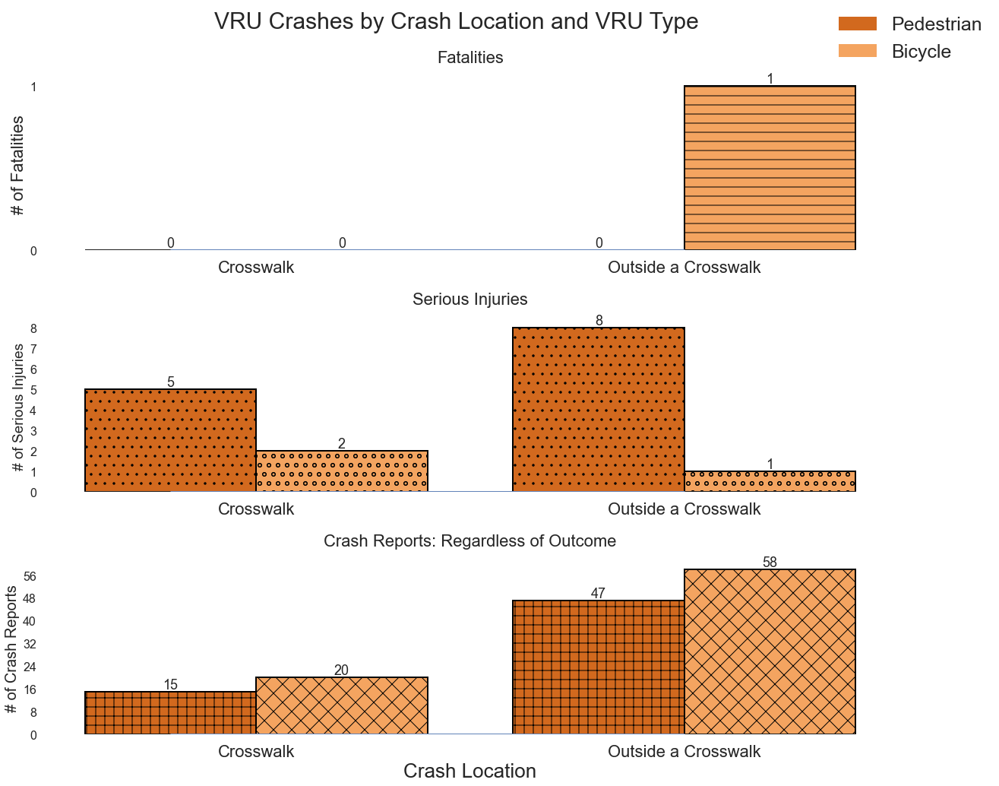

In [64]:
# test figure; once satisfied, run all seven to save separately from companion document
create_location_fig_vrus_type("NCR")

# Create final document

In [65]:
doc_name = './22-23/Drafted Deliverables/NPS TSP Regional Briefing Draft 22-23 - Testing.docx'
doc = docx.Document(doc_name)
styles = doc.styles
for s in styles:
    print(s)
print(styles)

_ParagraphStyle('Normal') id: 2003162829344
_ParagraphStyle('Heading 1') id: 2003162832128
_ParagraphStyle('Heading 2') id: 2003275538880
_ParagraphStyle('Heading 3') id: 2003276604368
_ParagraphStyle('Heading 6') id: 2003162847216
_ParagraphStyle('Heading 7') id: 2003162847264
_ParagraphStyle('Heading 8') id: 2003162846880
_ParagraphStyle('Heading 9') id: 2003162845968
_TableStyle('Normal Table') id: 2003275516464
_ParagraphStyle('toc 1') id: 2003275542336
_ParagraphStyle('toc 2') id: 2003275540800
_ParagraphStyle('toc 3') id: 2003276603792
_ParagraphStyle('Header') id: 2003162846976
_ParagraphStyle('Footer') id: 2003162845968
_TableStyle('Table Grid1') id: 2003276606720
_TableStyle('Table Grid') id: 2003275542336
_ParagraphStyle('List Paragraph') id: 2003162845920
_ParagraphStyle('annotation text') id: 2003276606720
_ParagraphStyle('annotation subject') id: 2003162847216
_ParagraphStyle('footnote text') id: 2003162847072
_ParagraphStyle('Normal (Web)') id: 2003275515024
_TableStyle('

In [66]:
def add_regional_information(region):
    df = make_source_table(region)
    doc_name = './22-23/Drafted Deliverables/NPS TSP Regional Briefing Draft 22-23 - blank.docx'
    doc = docx.Document(doc_name)
    doc.add_paragraph("ADD REGION NAME TO HEADER")
    doc.add_heading("Overview of Region")
    
    doc.add_heading("Available Data", 2)
    doc.add_paragraph("Crash and roadway characteristic data are the primary types of information important for understanding why crashes take place. The most effective safety strategies are developed by looking at datasets together. Table 1 shows the primary information sources, the number of Park units for which information is available, the range of years from which information originates, and the quantity of data available upon which the safety recommendations for this briefing are based. Note that the number of crash reports from CDS and IMARS listed in Table 1 only include records that could be attributed to a specific Park unit. See Section 1.1.1 for more details.")
    doc.add_paragraph("Table 1. Overview of Data Sources", style="Caption")
    t = doc.add_table(df.shape[0]+1, df.shape[1], style="Grid Table 5 Dark Accent 6")
    for j in range(df.shape[-1]):
        t.cell(0,j).text = df.columns[j]
    for i in range(df.shape[0]):
        for j in range(df.shape[-1]):
            t.cell(i+1,j).text = str(df.values[i,j])
            
    doc.add_heading("Description of Analysis Database", 3)
    doc.add_paragraph("All analyses in sections 1.2, 1.3.2, and 2.1 encompass a merged database of crashes recorded in STARS, CDS, or IMARS that took place between 1990 and 2021. Crash reports that included multiple vehicles or persons involved were aggregated to totals for the single crash. After doing so, duplicate crash reports (i.e., multiple crash records with the same crash identification number) were removed from the dataset to avoid redundant analysis.")
    doc.add_paragraph("Note that this dataset contains a subset of the total reported crashes from all three data systems during this period. Only crashes that could be attributed to a specific Park unit are included in the analysis database. The rationale for doing so is that a crash report without at least a generic location is not actionable for safety redress. This analysis decision resulted in a consolidated database from which all crashes could be partitioned into an NPS region for the respective regional briefings.")
    doc.add_paragraph("Park units for each crash were taken from the original crash reports, when available. The raw IMARS data included some crash records for which no Park name was entered, but latitude and longitude coordinates were included. For these crashes, Park names were identified by geospatially matching the coordinates provided with a shapefile of the NPS Park boundaries. Before doing so, erroneous crash coordinates were corrected to ensure the maximum possible geospatial matches within Park boundaries. Corrective actions included swapping latitude and longitude data for latitudes of magnitude greater than 70 decimal degrees and changing the sign of the coordinates as necessary to move the location to North America. The raw IMARS dataset also included some crash records for which no Park name or site coordinates were included, but other unambiguous descriptive site information was provided (e.g., road name listed as “Natchez Trace Parkway”). For these crashes, Park names were manually identified. Both the geospatial matching and manual Park identification methods significantly increased the number of IMARS crash reports that could be included in the analysis database, although Park units for some crash reports in the raw IMARS dataset were still unable to be assigned. These crash reports were excluded from the analysis database.")
    doc.add_paragraph("None of the CDS/STARS crash records without Park units explicitly included in the reports specified latitude and longitude coordinates with which to perform geospatial matching for Park name identification, so they were all excluded from the analysis database. However, some CDS/STARS crash records that already had Park units identified in the original crash reports also specified latitude and longitude coordinates. These coordinates were used to populate crash locations in the GIS web map. Thus, the same erroneous coordinate corrective actions executed on the IMARS raw data were also executed on the CDS/STARS dataset to improve the accuracy of the GIS web map.")
    doc.add_paragraph("Some CDS/STARS crash reports only included records in the data table containing general crash information, with empty records in the data tables containing additional details about the persons and vehicles involved in the crash. None of the IMARS crash reports for which Park names could be identified exhibited this data completeness issue. Much of the data analyses in sections 1.2 and 2.1 of this report rely on these additional person and vehicle details, so these incomplete CDS/STARS crash reports were also excluded from the analysis database for the sake of consistency IMARS. More information on this data completeness issue can be found in Section 1.3.1, where the incomplete CDS/STARS crash reports are categorized as “unlinked”.")
    doc.add_paragraph("ADD FOOTNOTES AND CROSS REFERENCES")
    
    doc.add_heading("Data Dictionary", 3)
    doc.add_paragraph("The following terms in Table 2 describe all input data and output metrics employed throughout the analyses.")
    doc.add_paragraph("ADD FOOTNOTES & CROSS REFERENCES AND ADJUST COLUMN WIDTH")
    doc.add_paragraph("Table 2:  Regional-Level Analysis Terms and Definitions", style="Caption")
    t = doc.add_table(data_dictionary.shape[0]+1, data_dictionary.shape[1], style="Grid Table 5 Dark Accent 1")
    for j in range(data_dictionary.shape[-1]):
        t.cell(0,j).text = data_dictionary.columns[j]
    for i in range(data_dictionary.shape[0]):
        for j in range(data_dictionary.shape[-1]):
            t.cell(i+1,j).text = str(data_dictionary.values[i,j])
            
    doc.add_heading("Data Analysis", 2)
    doc.add_heading("Park-Level Crashes", 3)
    doc.add_paragraph("Table 3 is included to highlight Parks for which crash safety projects may be of greater importance. The specific countermeasure(s) that may be most valuable to implement are explored in sections XYZ. The number of reported serious injuries and fatalities in Table 3 humanize the severe consequences of crashes. The number of crashes resulting in an injury or fatality provides context for the frequency of crashes inflicting injurious outcomes.")
    doc.add_paragraph("Note that the rows for each Park in Table 3 are sorted by number of fatalities, for which PARK ranks at the top. It should be emphasized that this ranking is based on the number of reported fatalities. It is possible that more fatalities may have occurred at a different Park in REGION, but not recorded in the crash reporting system. It is imperative that all severe injury outcomes be included in the crash reports in order to produce reliable analyses that can best inform decision making. This should be highlighted in law enforcement training on crash data reporting.")
    doc.add_paragraph("ADD CROSS REFERENCES")
    df = create_park_table(region)
    doc.add_paragraph("Table 3. Crash Outcomes by Park (1990-2021, data from STARS, CDS, IMARS)", style="Caption")
    t = doc.add_table(df.shape[0]+1, df.shape[1], style="Grid Table 5 Dark Accent 6")
    for j in range(df.shape[-1]):
        t.cell(0,j).text = df.columns[j]
    for i in range(df.shape[0]):
        for j in range(df.shape[-1]):
            t.cell(i+1,j).text = str(df.values[i,j])
    
    doc.add_heading("Crashes by Speed Limit", 3)
    doc.add_paragraph("Breaking down total crash reports and severe injury outcomes by crash site speed limit, as illustrated in Figure 1, is useful to determine whether severe injury outcomes are occurring on roadways with particular posted speed ranges more or less often than expected based on the distribution of total crash reports by crash site speed limit. Note the Y-axis scale difference between the three panes.")
    doc.add_paragraph("From this figure, it is evident that fatalities in REGION disproportionately occur on roadways with speed limits of XX mph relative to the smaller proportion of crashes recorded on roadways with those higher posted speeds. This suggests that reducing the posted speed on high-speed roads may in turn reduce roadway fatalities.")
    doc.add_paragraph("ADD CROSS REFERENCES")
    doc.add_paragraph("Figure 1. All Crashes by Speed Limit (1990-2021, data from STARS, CDS, IMARS)", style="Caption")
    create_posted_speed_fig(region)
    doc.add_picture('./22-23\Drafted Deliverables\Figures/Speed Limit Figures/' + region + ".png", width = 5943600, height = 4828270)
    doc.add_paragraph("Figure 2 illustrates the number of crashes resulting in an injury or fatality binned by crash site speed limit. The three panes compare the respective subsets of crashes involving VRUs and wildlife to all regional crash reports. Note the Y-axis scale difference between the three panes. Breaking down crashes resulting in an injury or fatality by crash site speed limit is intended to focus on the crashes in need of safety redress to determine whether injurious outcomes are occurring for each group on roadways with particular posted speed ranges more or less often than expected when compared with the crash site speed limit distribution of total injurious crash reports.")
    doc.add_paragraph('UPDATE THE FOLLOWING PARAGRAPH WITH REGION-SPECIFIC INFORMATION')
    doc.add_paragraph("From this figure, it is evident that injurious crashes involving wildlife disproportionately occur on roadways with speed limits above 40 mph relative to the few number of total reported injurious crashes on roadways with those high speed limits. This suggests that reducing the posted speed as well as implementing signage or roadway markings in locations near known wildlife habitats may in turn reduce injurious crashes involving wildlife. Education campaigns regarding vigilant driver attention may also be useful.")
    doc.add_paragraph("ADD CROSS REFERENCES")
    doc.add_paragraph("Figure 2. Crashes Resulting in an Injury or Fatality by Speed Limit (1990-2021, data from STARS, CDS, IMARS)", style="Caption")
    create_inj_or_fatal_fig(region)
    doc.add_picture('./22-23\Drafted Deliverables\Figures/Injury or Fatal Figures/' + region + ".png", width = 5943600, height = 4828270)
    doc.add_paragraph(" ")
    
    doc.add_heading("Crashes Involving Wildlife", 3)
    doc.add_paragraph('Table 4 displays the proportion and outcomes of crashes involving wildlife in the region, compared to the servicewide average. The number of reported serious injuries and fatalities humanize the severe consequences of crashes involving wildlife.')
    doc.add_paragraph('ADD CROSS REFERENCES AND REGION-SPECIFIC INTERPRETATION')
    df = create_wildlife_crashes_table(region)
    doc.add_paragraph("Table 4. Crashes Involving Wildlife, Regional and National (1990-2021, data from STARS, CDS, IMARS) ", style="Caption")
    t = doc.add_table(df.shape[0]+1, df.shape[1], style="Grid Table 5 Dark Accent 1")
    for j in range(df.shape[-1]):
        t.cell(0,j).text = df.columns[j]
    for i in range(df.shape[0]):
        for j in range(df.shape[-1]):
            t.cell(i+1,j).text = str(df.values[i,j])
    doc.add_paragraph(" ")
    doc.add_paragraph("Table 5 is included to highlight Parks for which mitigation strategies for crashes involving wildlife may be of greater importance. The specific countermeasure(s) that would be most valuable to implement are explored in the subsequent analyses. Note that Table 5 does not include rows for Parks that did not report any crashes involving wildlife, regardless of the crash outcome. Rows containing a Park name and zeros in all other columns indicate that the Park reported crash(es) involving wildlife that resulted in property damage only.")
    doc.add_paragraph("The rows for each Park in Table 5 are sorted by number of fatalities, for which PARK ranks at the top. PARK is ranked RANK because of the relatively high number of serious injuries. It should be emphasized that this ranking is based on the number of reported injuries and fatalities. It is possible that more fatalities may have occurred at different Parks in REGION, but not recorded in the crash reporting system. It is imperative that all severe injury outcomes be included in the crash reports in order to produce reliable analyses that can best inform decision making. This should be highlighted in law enforcement training on crash data reporting.")
    doc.add_paragraph("ADD CROSS REFERENCES")
    doc.add_paragraph("Table 5. Wildlife Crash Outcomes by Park (1990-2021, data from STARS, CDS, IMARS)", style="Caption")
    df = create_wildlife_crashes_table_park(region)
    t = doc.add_table(df.shape[0]+1, df.shape[1], style="Grid Table 5 Dark Accent 6")
    for j in range(df.shape[-1]):
        t.cell(0,j).text = df.columns[j]
    for i in range(df.shape[0]):
        for j in range(df.shape[-1]):
            t.cell(i+1,j).text = str(df.values[i,j])
    doc.add_paragraph(" ")
    doc.add_paragraph("Table 6 is included to better select safety measures based on the type of animal as strategies for reducing crashes involving bison differ from countermeasures to mitigate crash risk involving domestic animals, for example. Note that only IMARS contains data attributes to record the type of animal MISSING FOOTNOTE involved in a crash. As such, the low numbers in Table 6 compared to Table 4 and Table 5 may indicate that either most of the crashes involving wildlife were recorded in CDS, or there is a crash report completeness issue in IMARS wherein the type of animal data attribute is not being recorded. Law enforcement training on crash reporting should stress the importance of recording as much detail as possible within the given data system. Doing so provides decision makers with high-quality information so they can allocate safety project funds most effectively towards the areas of highest need.")
    doc.add_paragraph("Table 6. Wildlife Crash Outcomes by Type of Animal (1990-2021, data from STARS, CDS, IMARS)", style="Caption")
    df = create_wildlife_crashes_table_species(region)
    t = doc.add_table(df.shape[0]+1, df.shape[1], style="Grid Table 5 Dark Accent 1")
    for j in range(df.shape[-1]):
        t.cell(0,j).text = df.columns[j]
    for i in range(df.shape[0]):
        for j in range(df.shape[-1]):
            t.cell(i+1,j).text = str(df.values[i,j])
    doc.add_paragraph(" ")
    doc.add_paragraph("Figure 3 breaks down total crash reports involving wildlife and severe injury outcomes resulting from crashes involving wildlife by crash site speed limit. The speed limit segmentation was done in order to determine whether severe injury outcomes are occurring for crashes involving wildlife on roadways with particular posted speed ranges more or less often than expected based on the distribution of total crash reports involving wildlife by crash site speed limit. Note the Y-axis scale difference between the three panes.")
    doc.add_paragraph("As expected, Figure 3 clearly illustrates that fatalities resulting from crashes involving wildlife disproportionately occur on roadways with higher speed limits than most crash reports involving wildlife. Reducing the posted speed on roadways with existing speed limits above 40 mph may in turn reduce roadway fatalities. Furthermore, roadways with higher speed limits may not have dedicated crossing zones for wildlife, and drivers may not be expecting to encounter wildlife outside of those zones. As such, potential crash countermeasures in addition to posted speed reduction may include implementing wildlife crossing bridges, as well as roadway signage or markings to warn drivers well in advance of areas of known wildlife habitats. Education campaigns regarding vigilant driver attention may also be useful.")
    doc.add_paragraph("ADD CROSS REFERENCES AND UPDATE REGION-SPECIFIC INTERPRETATION")
    doc.add_paragraph("Figure 3. Wildlife Crashes by Speed Limit (1990-2021, data from STARS, CDS, IMARS)", style="Caption")
    create_posted_speed_fig_animals(region)
    doc.add_picture('./22-23\Drafted Deliverables\Figures/Wildlife Figures/' + region + ".png", width = 5943600, height = 4828270)
    
    doc.add_heading("Data Quality", 2)
    doc.add_heading("Crash Report Completeness by Data System", 3)
    doc.add_paragraph("Table 7 and Table 8 describe a larger dataset beyond what was included in the analysis database. The additional data are included to illustrate the quality of the raw crash reports by identifying data completeness issues that resulted in crashes that could not be analyzed.") 
    doc.add_paragraph('Crash reports categorized as "unlinked" in the third table columns were excluded from the analysis database because they are considered incomplete. Unlinked crash reports are missing passenger and vehicle report table entries, which include crucial information such as number of fatalities. Without this basic information, these unlinked crashes cannot be evaluated in a similar manner to the complete crash reports, and were therefore not included in the analysis.')
    doc.add_paragraph('Crash reports labeled as "missing coordinates" per the fourth table columns were still included in the analysis database, despite lacking important information. Missing specific crash locations in the crash records hinders analyst ability to identify crash hot spots and decisionmaker ability to effectively target safety programs in the highest value areas based on crash risk. Note that in Table 7, the term "coordinates" refers to crash report data in the universal latitude and longitude format, not the link and node format often used in CDS.')
    doc.add_paragraph('It appears that crash reporting is improving over time in that all data tables in IMARS were filled out 100% of the time, exemplified by the 0% of unlinked crashes. The proportion of crash reports with missing crash site coordinates also improved with the switch from the CDS to IMARS data systems, although REGION is still behind the national average. As such, training on crash reporting for law enforcement in REGION should emphasize the need to record crash site coordinates.')
    doc.add_paragraph("ADD CROSS REFERENCES")
    doc.add_paragraph("Table 7. CDS Crash Report Completeness, Regional and National (1989-2015)", style="Caption")
    df = create_data_quality_table_cds(region)
    t = doc.add_table(df.shape[0]+1, df.shape[1], style="Grid Table 5 Dark Accent 6")
    for j in range(df.shape[-1]):
        t.cell(0,j).text = df.columns[j]
    for i in range(df.shape[0]):
        for j in range(df.shape[-1]):
            t.cell(i+1,j).text = str(df.values[i,j])
    doc.add_paragraph(" ")
    doc.add_paragraph("Table 8. IMARS Crash Report Completeness, Regional and National (2013-2021)", style="Caption")
    df = create_data_quality_table_imars(region)
    t = doc.add_table(df.shape[0]+1, df.shape[1], style="Grid Table 5 Dark Accent 1")
    for j in range(df.shape[-1]):
        t.cell(0,j).text = df.columns[j]
    for i in range(df.shape[0]):
        for j in range(df.shape[-1]):
            t.cell(i+1,j).text = str(df.values[i,j])
    
    doc.add_heading("Crash Location Coordinates by Year", 3)
    doc.add_paragraph("The Y-axis of Figure 4 and Figure 5 exhibit the annual number of respective serious injuries and fatalities reported by each data system. The plot area color indicates the proportion of crash reports recording those severe crash outcomes that were geolocated to a specific crash site by including latitude and longitude coordinates. Note that the lighter color areas with hatching comprise a subset of the darker color areas without hatching, which represent the entire analysis database, regardless of crash site coordinate fill rate.")
    doc.add_paragraph("This analysis does not attempt to evaluate the accuracy or precision of the given crash site coordinates, just the fill rate of the latitude and longitude fields in the crash report. The intention of this analysis is to humanize the consequence of incomplete crash reporting. Crash countermeasures cannot be implemented in order to reduce severe crash outcomes without knowing where the crashes took place. Law enforcement training on crash reporting should stress the importance of recording latitude and longitude crash site coordinates as doing so empowers decisionmakers to allocate safety project funds most effectively towards the areas of highest need.")
    doc.add_paragraph("The big picture of Figure 4 and Figure 5 demonstrate a general increase in coordinate fill rate over time for crashes resulting in severe crash outcomes. However, geolocation worsens starting in 2019 as the number of severe injury outcomes without reported crash site coordinates is growing. Note that the general contour of Figure 4 exhibiting fewer serious injuries over time regardless of the coordinate fill rate does not necessarily indicate increased regional safety. This trend may instead be reflective of a decline in crash reporting over time.")
    doc.add_paragraph("ADD CROSS REFERENCES AND UPDATE REGION-SPECIFIC INTERPRETATION")
    make_yearly_crash_fig(region)
    doc.add_paragraph("Figure 4. Annual Regional Serious Injuries by Data System and Georeference Quality", style="Caption")
    doc.add_picture('./22-23\Drafted Deliverables\Figures/Data Quality Tables/' 'serious injury-' + region + ".png", width = 5943600, height = 3447288)
    doc.add_paragraph(" ")
    doc.add_paragraph("Figure 5. Annual Regional Fatalities by Data System and Georeference Quality", style="Caption")
    doc.add_picture('./22-23\Drafted Deliverables\Figures/Data Quality Tables/' 'fatality-' + region + ".png", width = 5943600, height = 3447288)
    doc.add_paragraph(" ")
    
    doc.add_heading("Crash Location Accuracy by Park", 3)
    doc.add_paragraph("Figure 6 illustrates crash site georeference quality in IMARS FOOTNOTE crash reports. The visualization focuses on ten Parks with the most IMARS crash reports containing latitude and longitude data. The plot displays the proportion of crash reports in a series of bins in increasing order of magnitude distance from the official Park boundary. The crash report georeference accuracy decreases by bin from bottom to top of the plot (i.e., the green bins without hatching represent the subset of crash reports with the most accurate coordinate data and the red bins without hatching represent the subset of crash reports with the least accurate coordinate data. The grey bins with hatching represent the subset of crash reports for which coordinate accuracy could not be evaluated because no coordinates were reported). Note that this measurement of “accuracy” does not represent how close the reported coordinates are to the actual crash location, as that cannot be evaluated based on the available data. In this analysis, “accuracy” refers to how close the recorded the crash site is to being located within the boundary of the Park unit listed in the crash report.")
    doc.add_paragraph("Across the top 10 REGION Parks, only X Parks reported a majority of crash sites in IMARS that were actually located within the reported Park boundary. Furthermore, Y Parks reported a majority of crashes in IMARS with no coordinates at all. As previously mentioned, the consequence of not recording crash site coordinates is that nothing can be done to mitigate crash risk or reduce severity of crash outcomes. Law enforcement training on crash reporting should include how to accurately determine and record the crash site coordinates. Doing so provides decision makers with high quality information so they can allocate safety project funds most effectively towards the areas of highest need.")
    doc.add_paragraph("ADD CROSS REFERENCES AND UPDATE REGION-SPECIFIC INTERPRETATION")
    make_coordinate_bin_fig(region)
    doc.add_paragraph("Figure 6. IMARS Lat/Long Distance from Park Boundary for Top 10 Parks", style="Caption")
    doc.add_picture('./22-23\Drafted Deliverables\Figures/IMARS Coordinate Geolocation Figures/' + region + ".png", width = 5943600, height = 3447288)
    doc.add_paragraph(" ")    
    
    doc.add_heading("Wish List Items")
    doc.add_heading("Crashes Involving Vulnerable Road Users", 2)
    doc.add_paragraph("NOTE: REMOVE THIS SECTION FOR REGIONS WHO DID NOT ASK FOR IT")
    df = create_vru_crashes_table(region)
    doc.add_paragraph("Table 9 compares the proportion and outcomes of crashes involving VRUs in the region, compared to the servicewide average. The number of reported serious injuries and fatalities humanize the severe consequences of crashes involving VRUs. Note that although crashes involving VRUs constitute a small proportion of the total reported crashes, they are much more likely to result in an injury or fatality in REGION. This indicates that despite being relatively infrequent, crashes involving VRUs are in critical need of safety improvements to reduce the high likelihood of severe injury outcomes in REGION.") 
    doc.add_paragraph("Table 9. Crashes Involving VRUs, Regional and National (1990-2021, data from STARS, CDS, IMARS) ", style="Caption")
    doc.add_paragraph("ADD CROSS REFERENCES")
    t = doc.add_table(df.shape[0]+1, df.shape[1], style="Grid Table 5 Dark Accent 6")
    for j in range(df.shape[-1]):
        t.cell(0,j).text = df.columns[j]
    for i in range(df.shape[0]):
        for j in range(df.shape[-1]):
            t.cell(i+1,j).text = str(df.values[i,j])
    
    doc.add_heading("VRU Crashes by Park", 3)
    doc.add_paragraph("Table 10 is included to highlight Parks for which VRU safety projects may be of greater importance. The specific countermeasure(s) that would be most valuable to implement are explored in the subsequent data visualizations. Note that Table 10 does not include rows for Parks that did not report any crashes involving VRUs, regardless of the crash outcome. Rows containing a Park name and zeros in all other columns indicate that the Park reported crash(es) involving VRUs that resulted in property damage only.")
    doc.add_paragraph("The rows for each Park in Table 10 are sorted by number of fatalities, for which PARK is ranked first. It should be emphasized that this ranking is based on the number of reported fatalities. It is possible that more fatalities may have occurred at a different Park in REGION, but not recorded in the crash reporting system. It is imperative that all severe injury outcomes be included in the crash reports in order to produce reliable analyses that can best inform decision making. This should be highlighted in law enforcement training on crash data reporting.")
    doc.add_paragraph("ADD CROSS REFERENCES")
    doc.add_paragraph("Table 10. VRU Crash Outcomes by Park (1990-2021, data from STARS, CDS, IMARS)", style="Caption")
    df = create_vru_crashes_table_park(region)
    t = doc.add_table(df.shape[0]+1, df.shape[1], style="Grid Table 5 Dark Accent 1")
    for j in range(df.shape[-1]):
        t.cell(0,j).text = df.columns[j]
    for i in range(df.shape[0]):
        for j in range(df.shape[-1]):
            t.cell(i+1,j).text = str(df.values[i,j])
    
    doc.add_heading("VRU Crash Site Speed Limit", 3)
    doc.add_paragraph("Figure 7 breaks down total crash reports involving VRUs and severe injury outcomes resulting from crashes involving VRUs by crash site speed limit. The speed limit segmentation was done in order to determine whether severe injury outcomes are occurring for crashes involving VRUs on roadways with particular posted speed ranges more or less often than expected based on the distribution of total crash reports involving VRUs by crash site speed limit. Note the Y-axis scale difference between the three panes.")
    doc.add_paragraph("As expected, Figure 7 clearly illustrates that fatalities resulting from crashes involving VRUs disproportionately occur on roadways with higher speed limits than most crash reports involving VRUs. This indicates the intuitive conclusion that higher speed limits are more deadly for crashes involving VRUs. Reducing the posted speed on roadways with existing speed limits above 40 mph may in turn reduce roadway fatalities, especially from crashes involving VRUs. Furthermore, roadways with higher speed limits may not have dedicated crossing zones for VRUs, and drivers may not be expecting to encounter VRUs outside of those zones. As such, potential crash countermeasures in addition to posted speed reduction may include implementing signage or roadway markings to warn drivers in advance of areas of known dense VRU activity. Education campaigns regarding vigilant driver attention may also be useful.")
    doc.add_paragraph("ADD CROSS REFERENCES AND UPDATE REGION-SPECIFIC INTERPRETATION")
    doc.add_paragraph("Figure 7. Vulnerable Road User Crashes by Speed Limit (1990-2021, data from STARS, CDS, IMARS)", style="Caption")
    create_posted_speed_fig_vrus(region)
    doc.add_picture('./22-23\Drafted Deliverables\Figures/VRU Figures/' + region + ".png", width = 5943600, height = 4828270)
    
    doc.add_heading("VRU Crash Location", 3)
    doc.add_paragraph("Figure 8 partitions total crash reports involving VRUs and severe injury outcomes resulting from crashes involving VRUs by crash location, categorized as in or outside of a crosswalk. Crash location distinction can help improve safety measures in areas of known dense VRU activity. The visualization illustrates whether severe injury outcomes are occurring for crashes involving VRUs in or outside of crosswalks more or less often than expected based on the breakdown of total crash reports involving VRUs by crash location. Note the Y-axis scale difference between the three panes.")
    doc.add_paragraph("The results of this analysis support the previous analyses that established higher speed roadways as more deadly, especially for crashes involving VRUs. Higher speed roadways also tend not to have crosswalks. Figure 8 shows that areas outside of crosswalks are much more dangerous for VRUs as there are far more crashes and serious outcomes from those crashes at those locations. This might suggest more crosswalks are needed for safer multimodal intersections, but it could also mean that safer routes to walk or bike along higher speed roadways are of greater need. Education campaigns regarding vigilant driver attention and safe VRU crossing practices may also be useful.")
    doc.add_paragraph("ADD CROSS REFERENCES AND UPDATE REGION-SPECIFIC INTERPRETATION")
    doc.add_paragraph("Figure 8. Vulnerable Road User Crashes by Location (1990-2021, data from STARS, CDS, IMARS)", style="Caption")
    create_location_fig_vrus(region)
    doc.add_picture('./22-23\Drafted Deliverables\Figures/Crosswalk Figures/' + region + ".png", width = 5943600, height = 4828270)
    
    doc.add_heading("Decomposition of VRU Types", 3)
    doc.add_paragraph("Figure 9 illustrates the ratio of pedestrians and cyclists encompassed within VRU crashes and serious crash outcomes. Figure 10 and Figure 11 display the same statistics as Figure 7 and Figure 8, with additional decomposition by VRU type. The added granularity from these figures is useful to select the most effective safety project, as strategies for reducing crashes involving pedestrians may differ from countermeasures to mitigate crash risk involving cyclists. Note the Y-axis scale difference between the three panes in each figure. Also note that the separate pedacylist category was dropped for these visualizations due to low sample size, but crash reports in which pedacylists are specifically mentioned are included in the overall VRU data analyses in Table 9, Table 10, Figure 7, and Figure 8.")
    doc.add_paragraph("ADD CROSS REFERENCES AND REGION-SPECIFIC INTERPRETATION")
    doc.add_paragraph("Figure 9. Vulnerable Road User Crashes by User Type (1990-2021, data from STARS, CDS, IMARS)", style="Caption")
    create_type_fig_vrus(region)
    doc.add_picture('./22-23\Drafted Deliverables\Figures/VRU Figures/' 'VRU-types-' + region + ".png", width = 5943600, height = 4828270)
    doc.add_paragraph("Figure 10. Vulnerable Road User Crashes by Speed Limit and User Type (1990-2021, data from STARS, CDS, IMARS)", style="Caption")
    create_posted_speed_fig_vrus_type(region)
    doc.add_picture('./22-23\Drafted Deliverables\Figures/VRU Figures/' 'type_and_speed_' + region + ".png", width = 5943600, height = 4828270)
    doc.add_paragraph(" ")
    doc.add_paragraph("Figure 11. Vulnerable Road User Crashes by Location and User Type (1990-2021, data from STARS, CDS, IMARS)", style="Caption")
    create_location_fig_vrus_type(region)
    doc.add_picture('./22-23\Drafted Deliverables\Figures/Crosswalk Figures/' 'type-' + region + ".png", width = 5943600, height = 4828270)
    doc.add_paragraph(" ")
  
    doc_name_new = './22-23/Drafted Deliverables/NPS TSP Regional Briefing Draft 22-23 - ' + region + ".docx"
    
    doc.save(doc_name_new)

<ipython-input-45-614f1c3e4d02>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['ones'] = 1
<ipython-input-47-e0601b3aa529>:42: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(['{:.0%}'.format(y) for y in y_vals], fontsize=15)


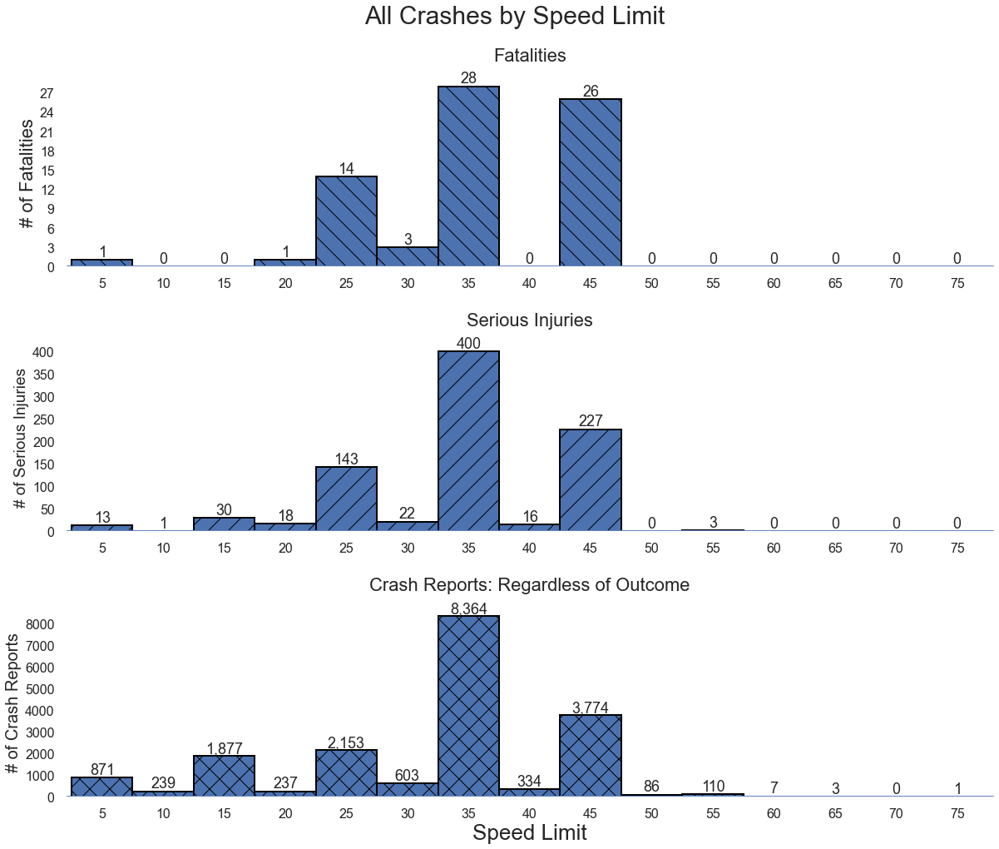

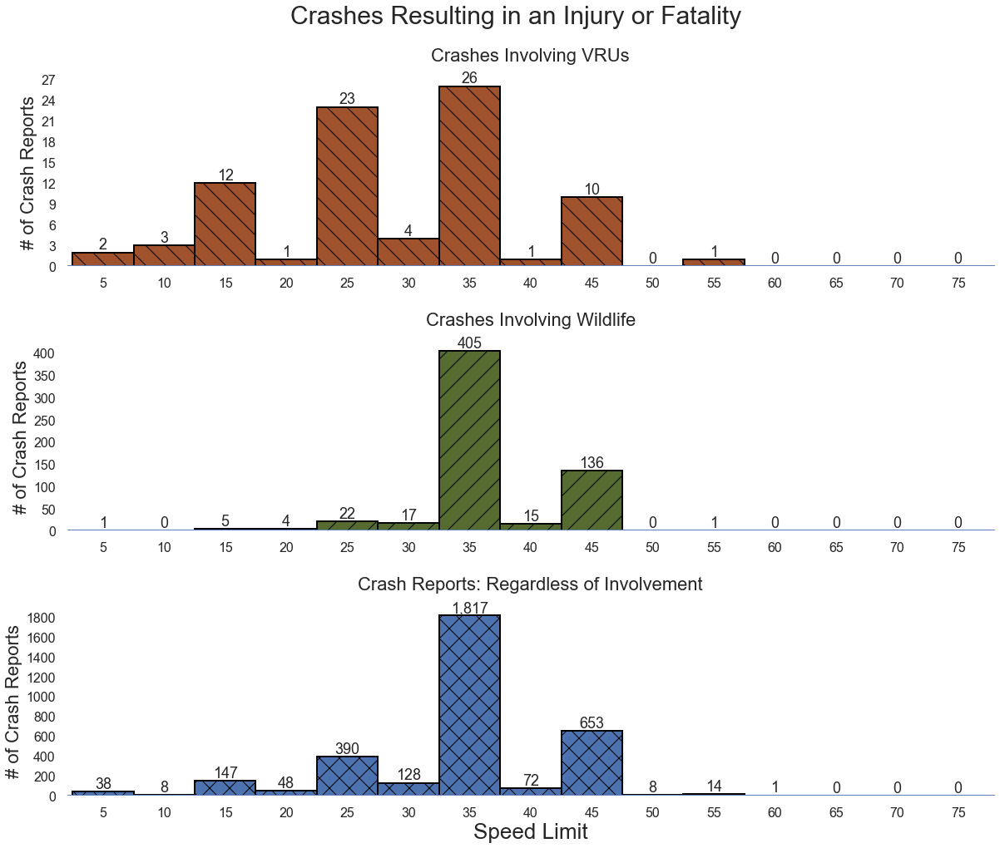

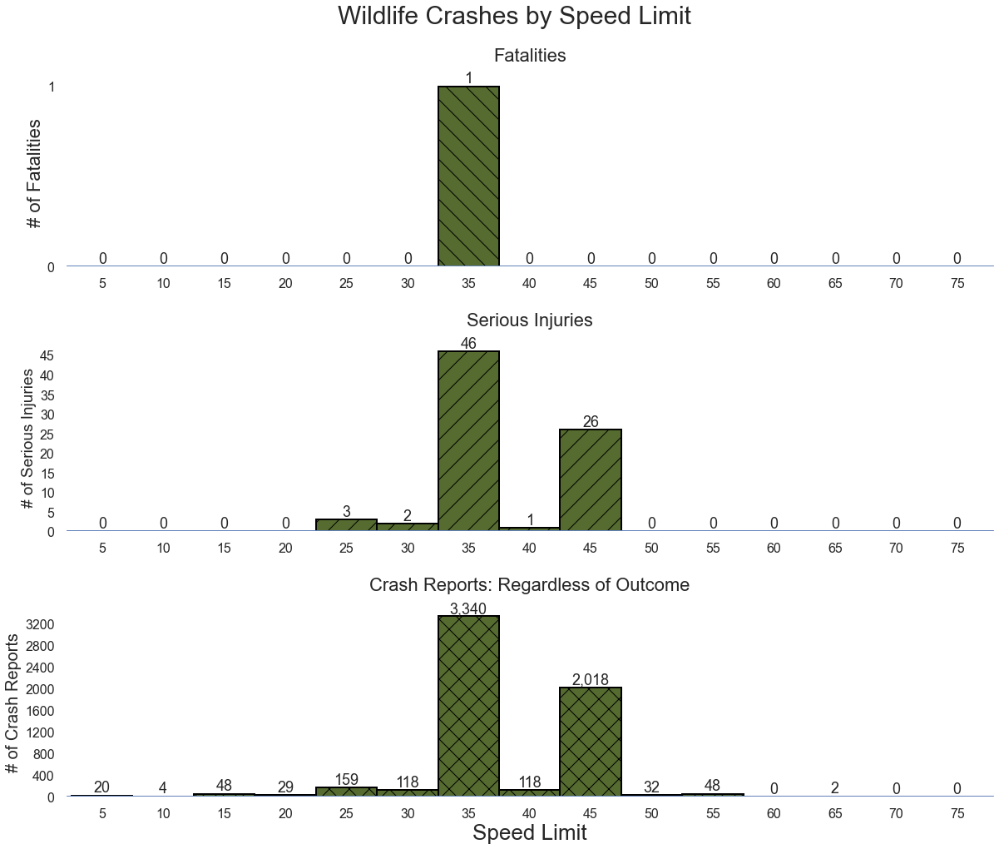

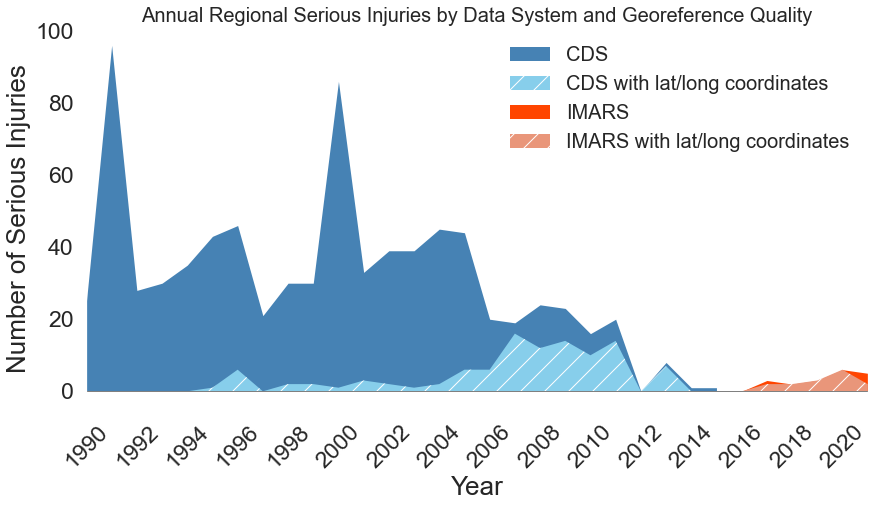

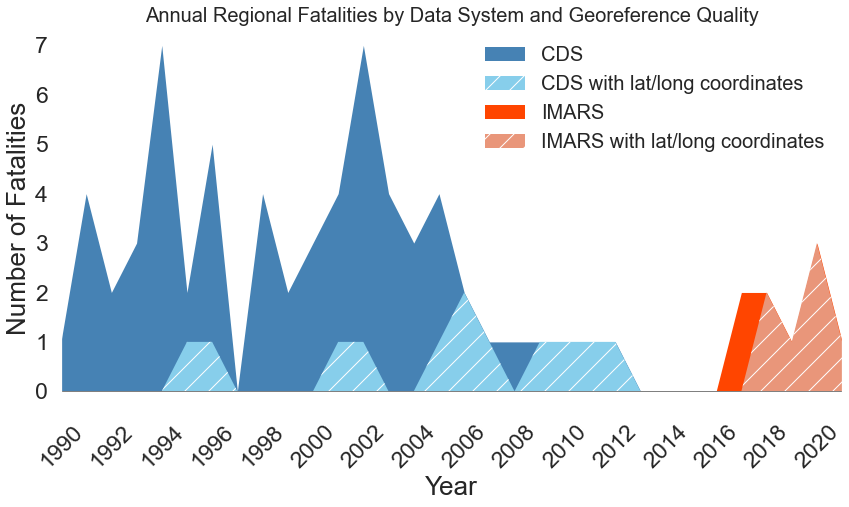

...

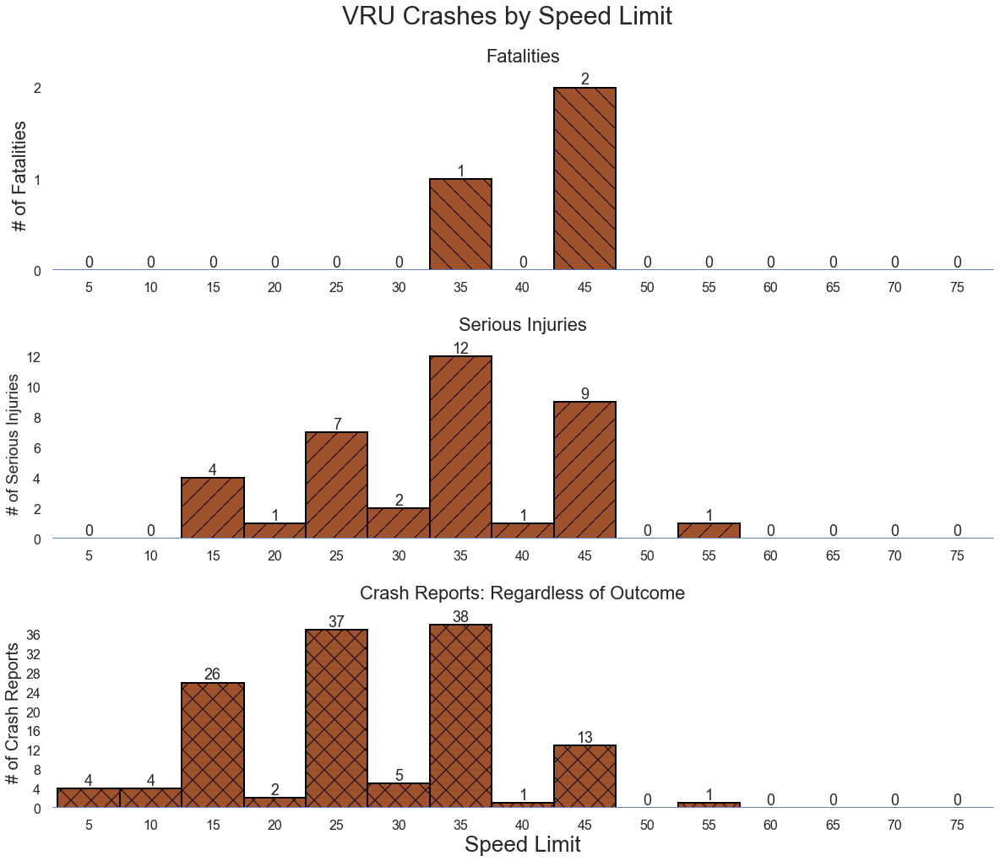

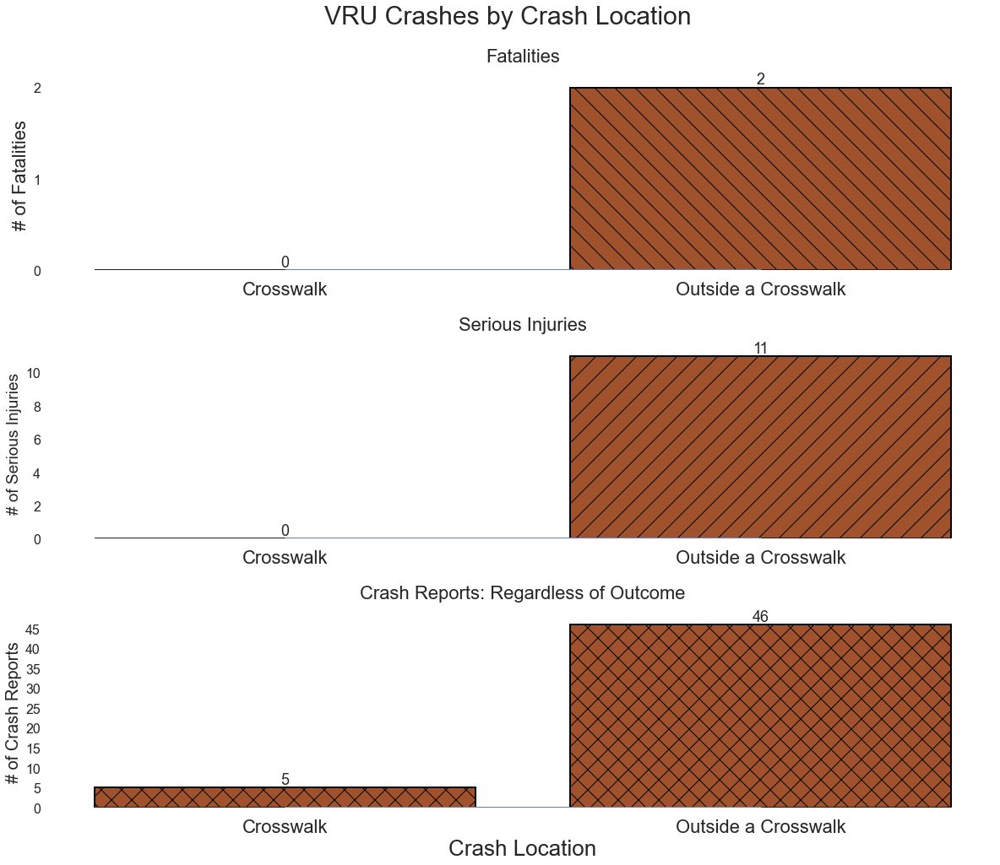

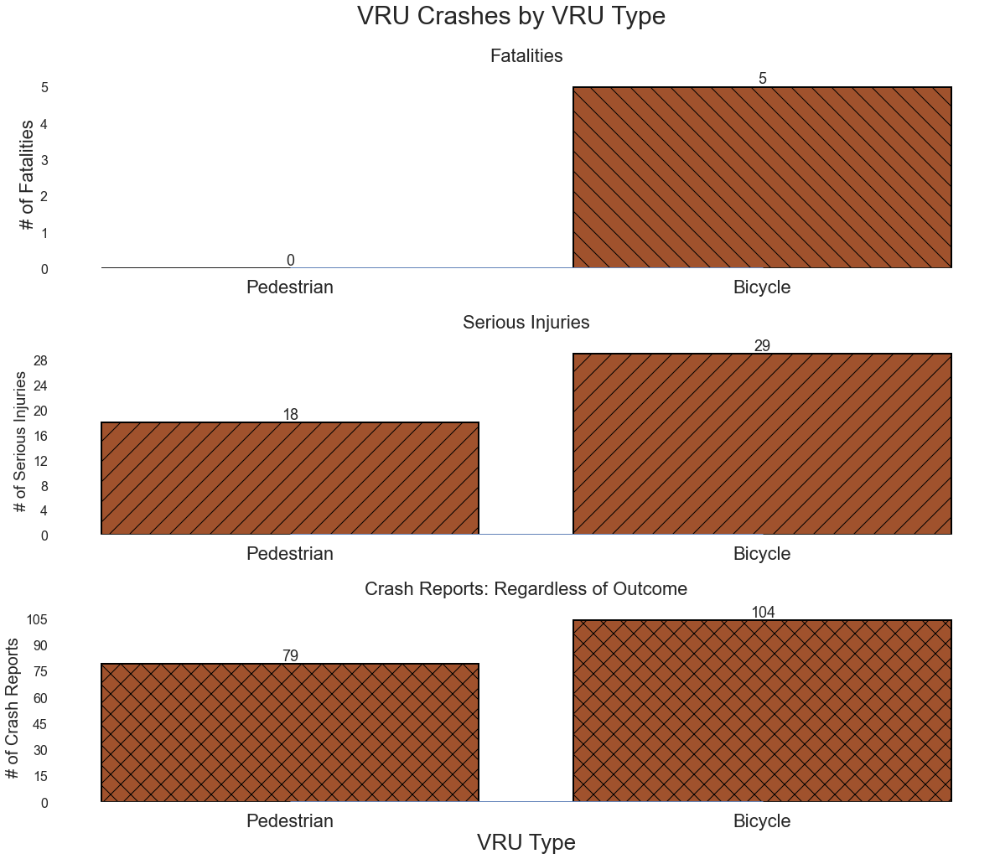

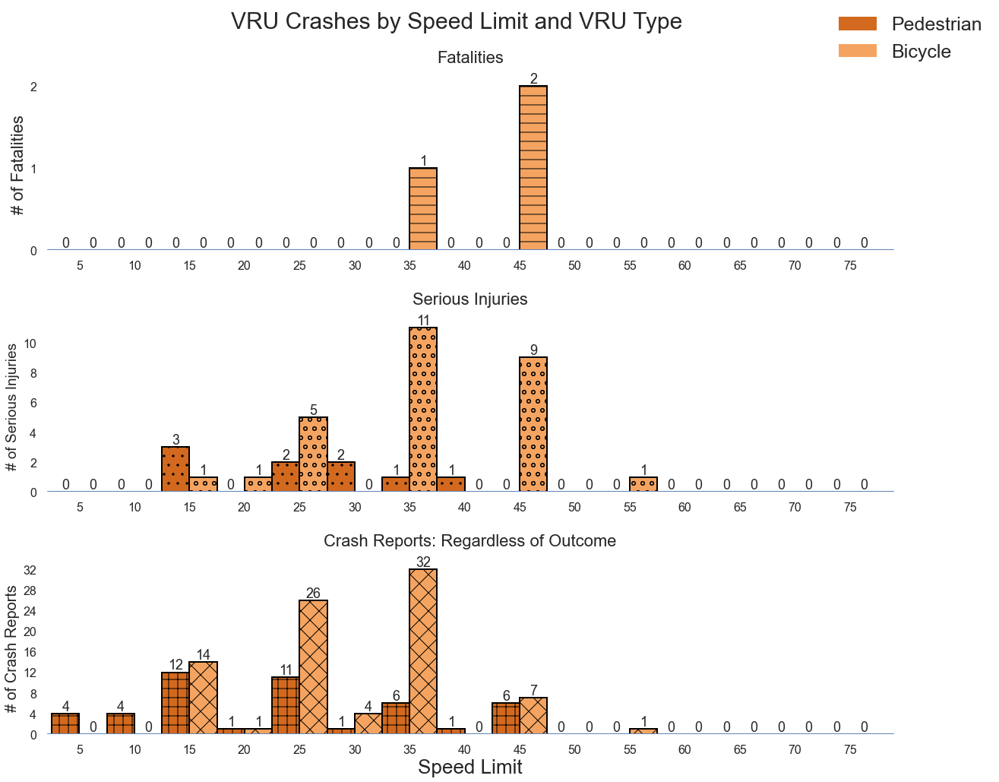

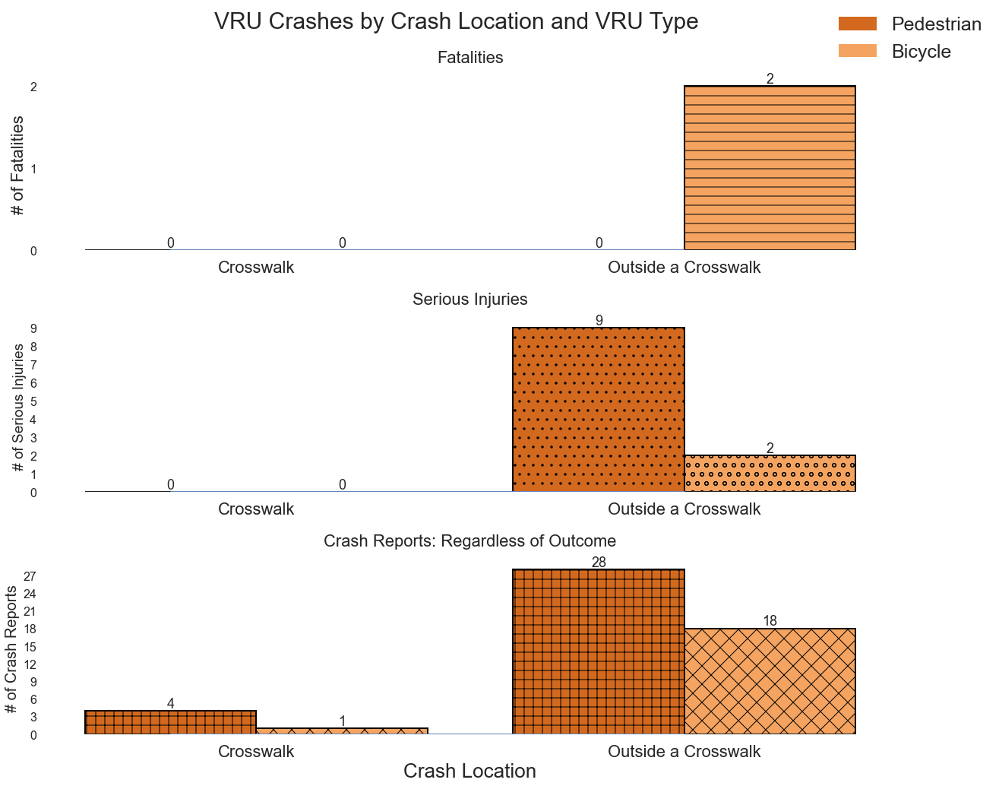

In [68]:
# test document creation for one region
add_regional_information("NER")

SER


C:\Users\Eric.Englin\AppData\Local\Temp\ipykernel_19940\3417642403.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['ones'] = 1
C:\Users\Eric.Englin\AppData\Local\Temp\ipykernel_19940\1041171165.py:42: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(['{:.0%}'.format(y) for y in y_vals], fontsize=15)


NER


C:\Users\Eric.Englin\AppData\Local\Temp\ipykernel_19940\3417642403.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['ones'] = 1
C:\Users\Eric.Englin\AppData\Local\Temp\ipykernel_19940\1041171165.py:42: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(['{:.0%}'.format(y) for y in y_vals], fontsize=15)
C:\Users\Eric.Englin\AppData\Local\Temp\ipykernel_19940\22902922.py:43: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  fig, ax = plt.subplots(3,1,figsize=(20,15))


MWR


C:\Users\Eric.Englin\AppData\Local\Temp\ipykernel_19940\3417642403.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['ones'] = 1
C:\Users\Eric.Englin\AppData\Local\Temp\ipykernel_19940\1041171165.py:42: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(['{:.0%}'.format(y) for y in y_vals], fontsize=15)


... (4 outputs left out)

PWR


C:\Users\Eric.Englin\AppData\Local\Temp\ipykernel_19940\3417642403.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['ones'] = 1
C:\Users\Eric.Englin\AppData\Local\Temp\ipykernel_19940\1041171165.py:42: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(['{:.0%}'.format(y) for y in y_vals], fontsize=15)


AKR


C:\Users\Eric.Englin\AppData\Local\Temp\ipykernel_19940\3417642403.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['ones'] = 1
C:\Users\Eric.Englin\AppData\Local\Temp\ipykernel_19940\1041171165.py:42: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(['{:.0%}'.format(y) for y in y_vals], fontsize=15)


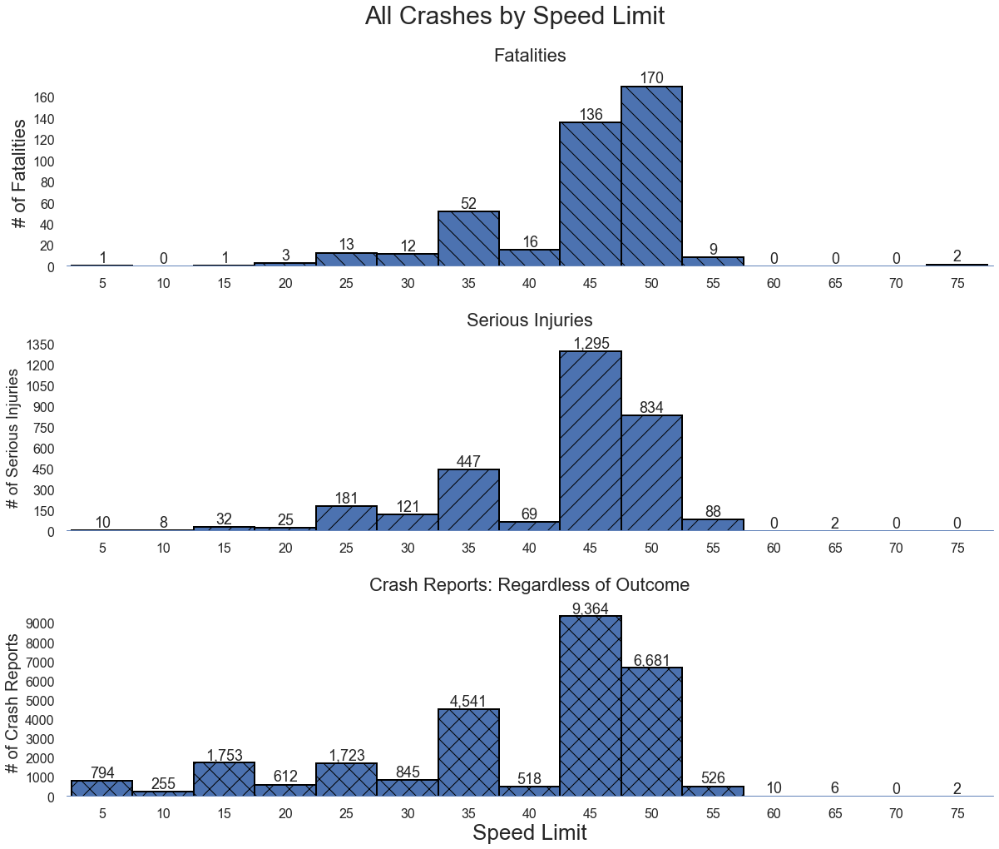

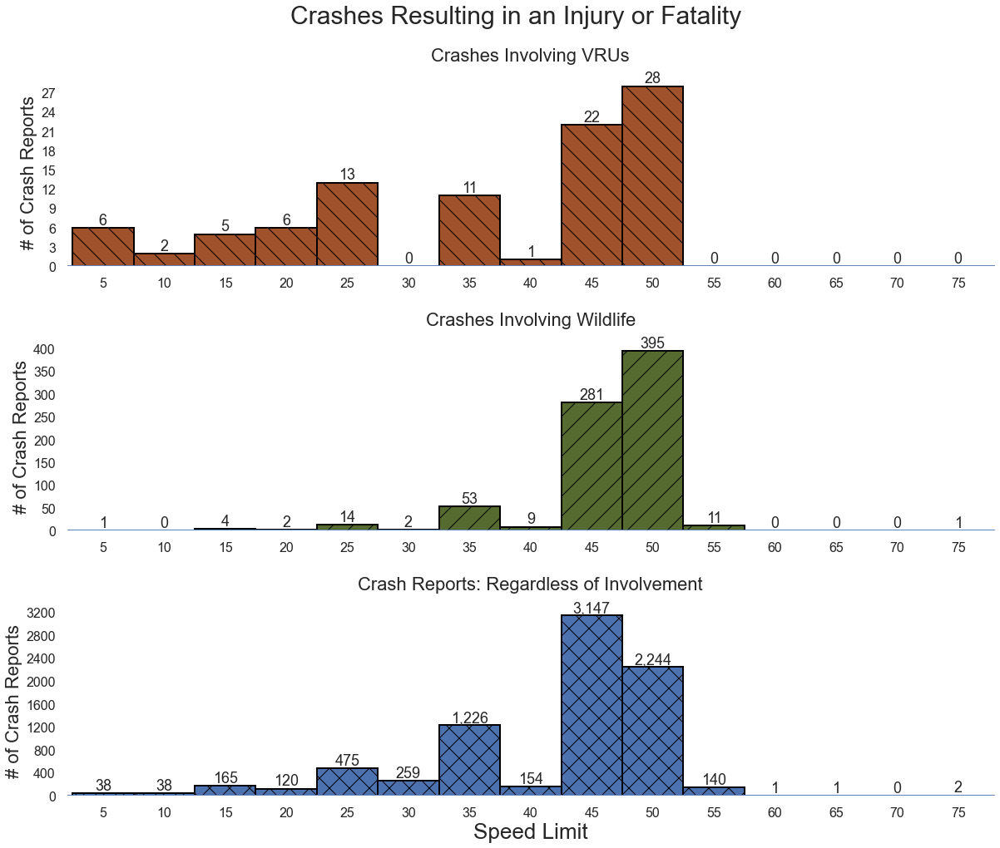

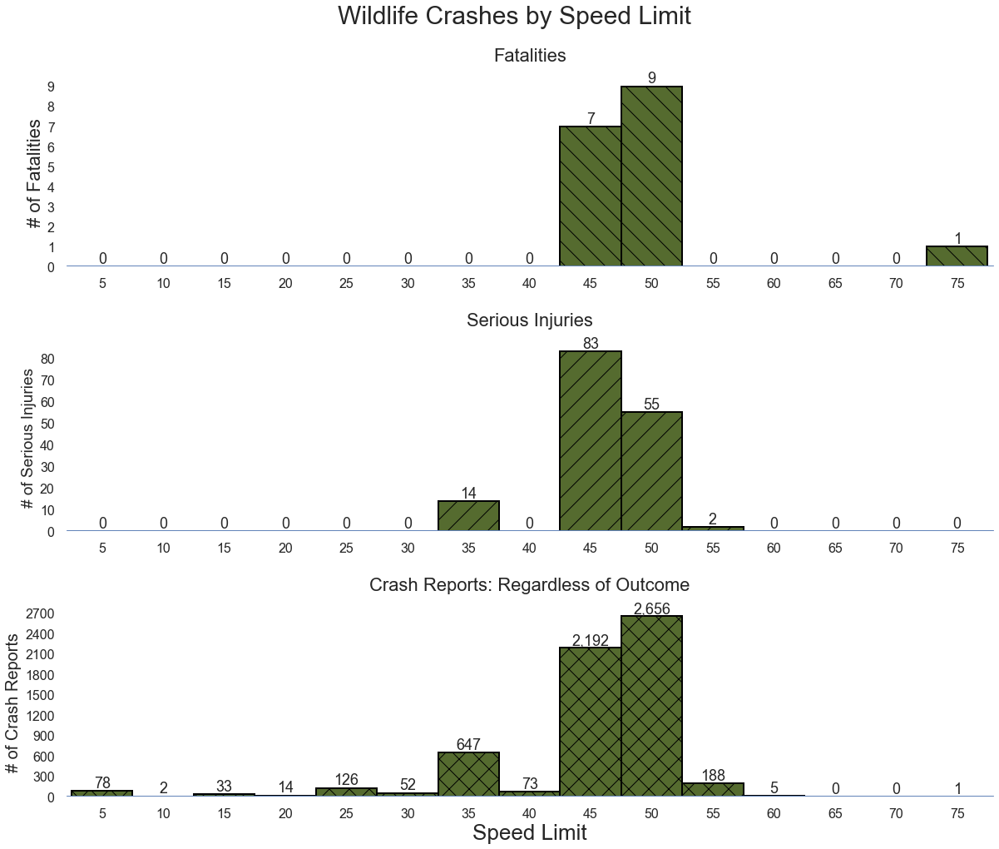

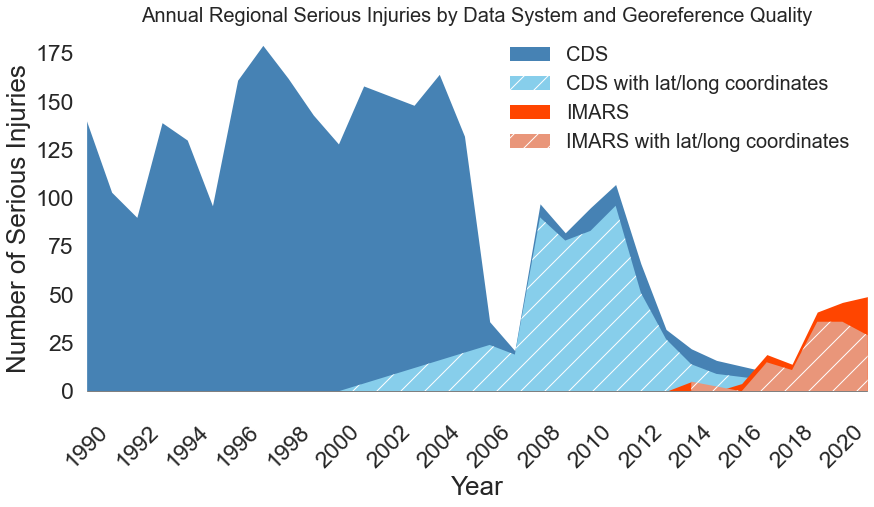

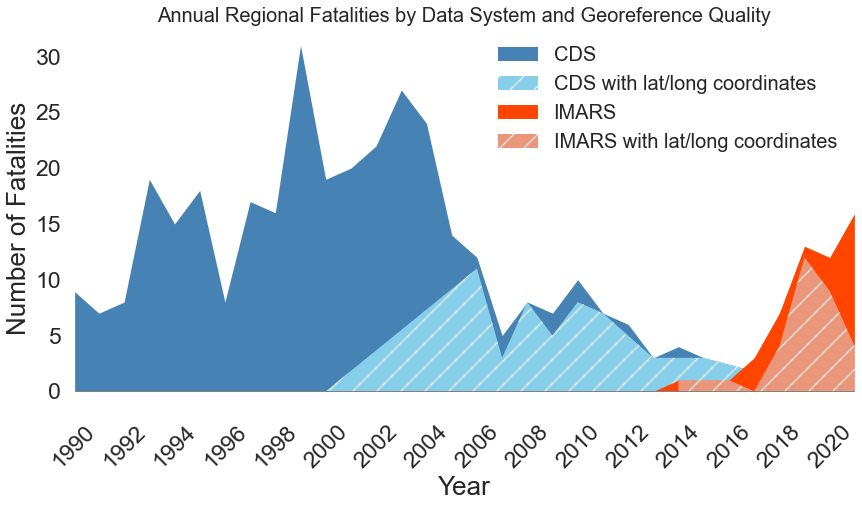

...

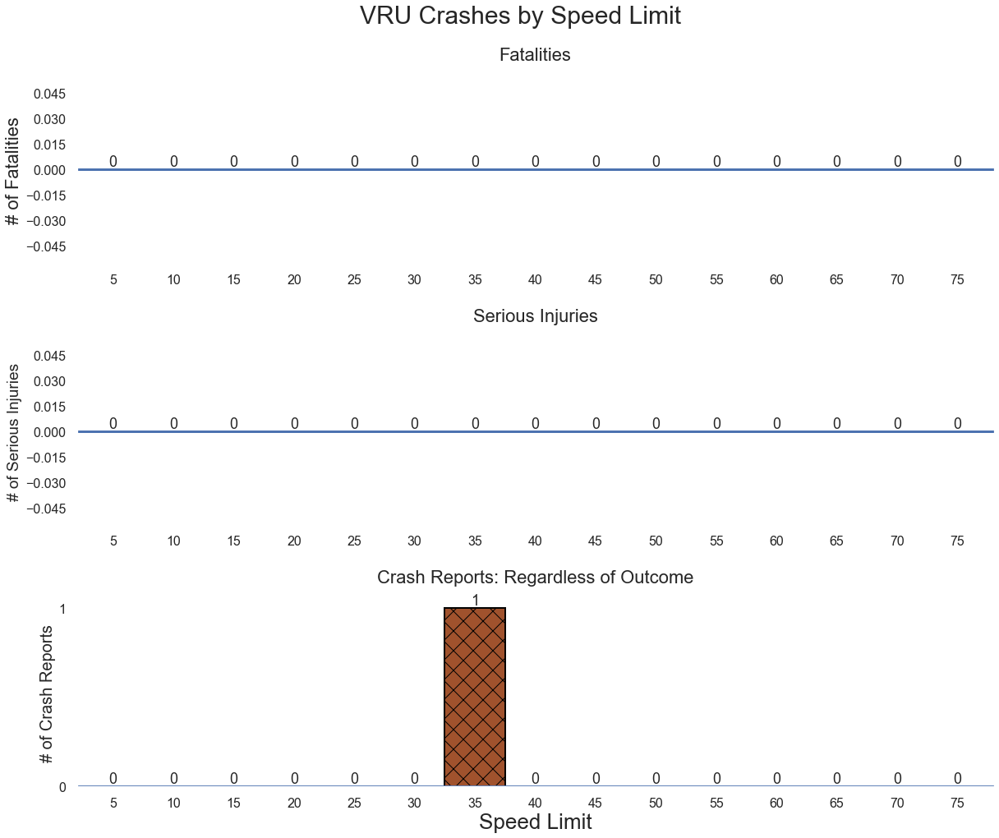

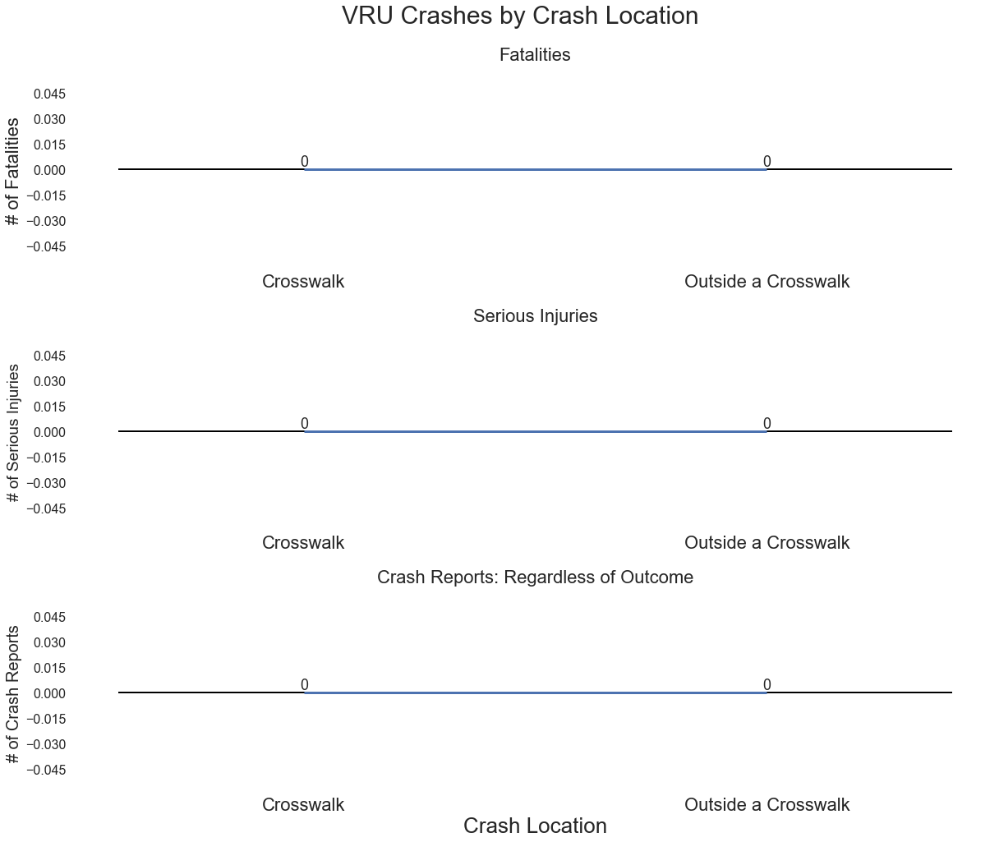

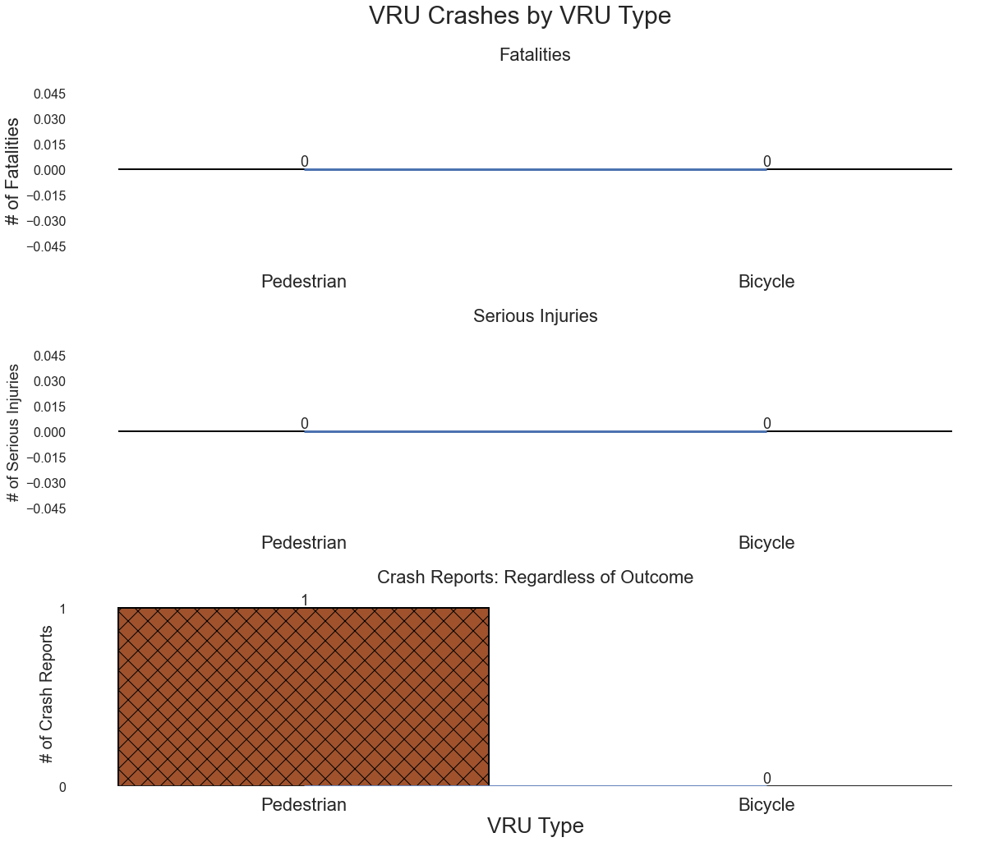

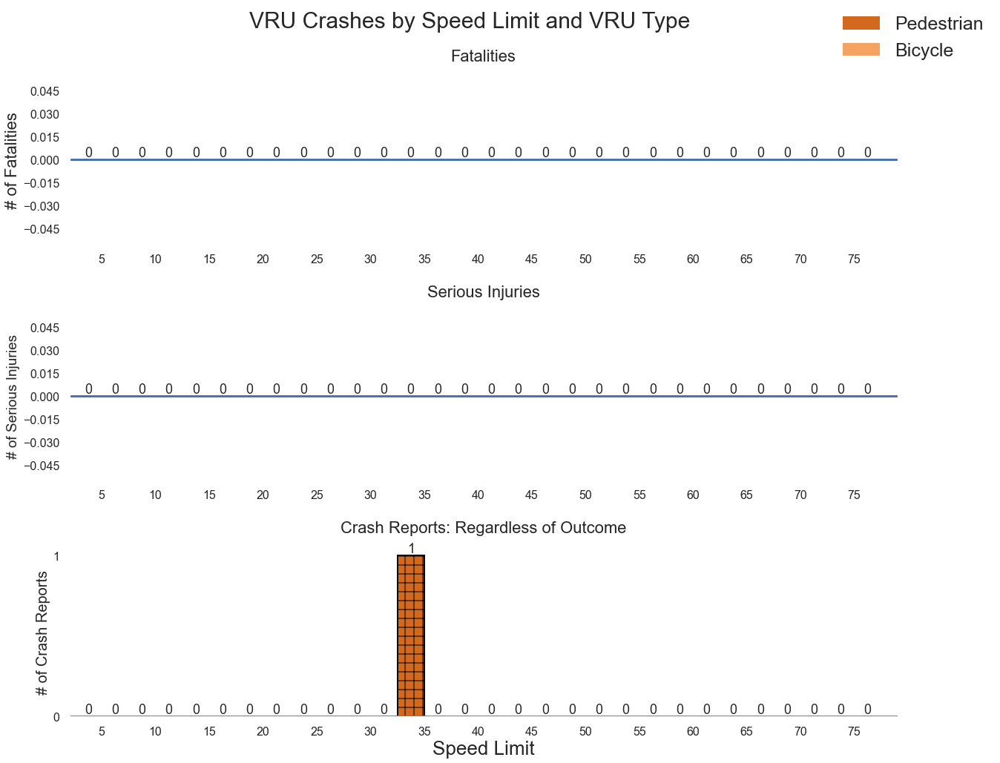

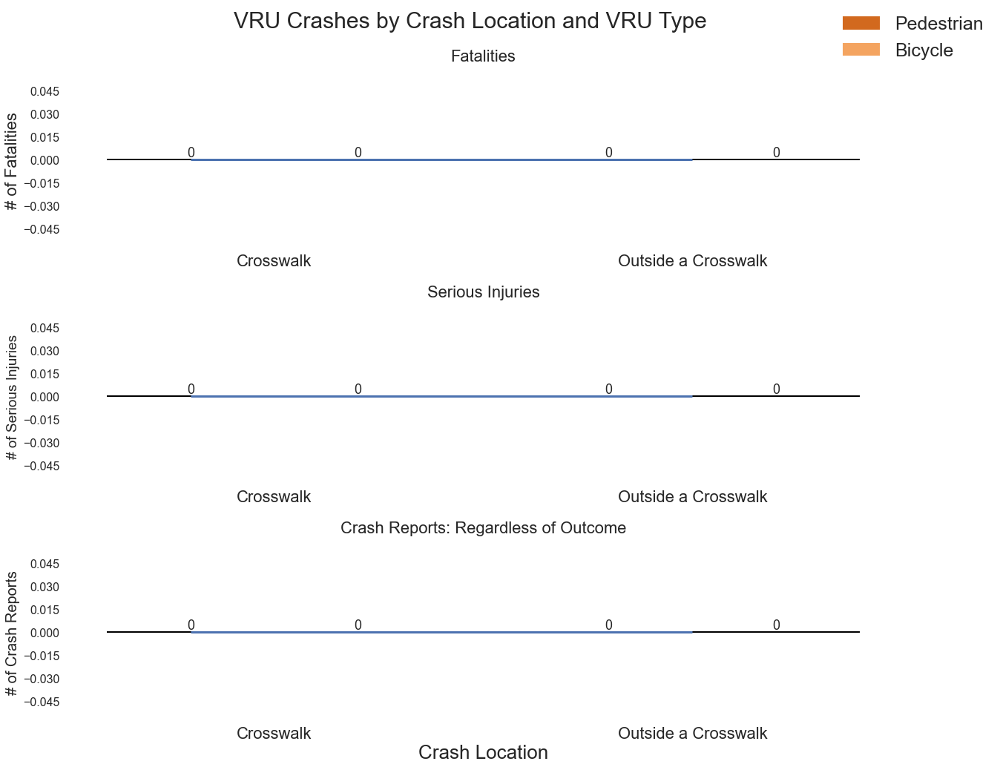

In [319]:
# run document creation for all regions
for x in analysis_2022.RGN.unique():
    print(x)
    add_regional_information(x)

In [320]:
# print list of regions to ensure all are covered
for x in analysis_2022.RGN.unique():
    print(x)

SER
NER
MWR
IMR
NCR
PWR
AKR
